# UTS Milestone 1 — Deteksi Transaksi Fraud pada Mobile Money (PaySim)

| | |
|---|---|
| **Project ID** | `B12` |
| **Kelompok** | `Kelompok 3` |
| **Anggota** | `[1. Muhammad Aswan Taqiy (231112002), 2. Steven Raffael Antonius Sidauruk (231112060), 3. William Patar Wijaya Marpaung (231112393)]` |
| **Topik** | Aktivitas Transaksi Digital yang Tidak Wajar |
| **Dataset** | PaySim — *Synthetic Financial Datasets For Fraud Detection* (Kaggle, versi 2) |


## Persiapan

In [32]:
import gc
import glob
import hashlib
import json
import os
import platform
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler
from sklearn.tree import DecisionTreeClassifier

WAKTU_MULAI = time.time()

RANDOM_STATE = 42
N_FOLD = 5
PORSI_TRAIN = 0.80                       # 80% baris paling awal menurut waktu
LINGKUP_TIPE = ["TRANSFER", "CASH_OUT"]

DIR_HASIL = Path("results")
DIR_GAMBAR = Path("figures")
DIR_HASIL.mkdir(exist_ok=True)
DIR_GAMBAR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

M = {}   # seluruh angka yang dikutip teks notebook dan laporan; disimpan ke results/metrics.json

print("Python      :", platform.python_version())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)

Python      : 3.13.15
pandas      : 3.0.6
numpy       : 2.5.3
scikit-learn: 1.9.1
matplotlib  : 3.11.2


In [33]:
# Gaya grafik: satu sumbu per panel, garis bantu tipis, warna mengikuti entitas (normal = biru, fraud = oranye).
TINTA, TINTA2, GRID, GARIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
WARNA_KELAS = {"normal": "#2a78d6", "fraud": "#eb6834"}
WARNA_MODEL = {"LR": "#2a78d6", "DT": "#eb6834", "RF": "#1baf7a", "HGB": "#eda100"}

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "axes.edgecolor": GARIS, "axes.linewidth": 0.8, "axes.grid": True, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlecolor": TINTA, "axes.labelcolor": TINTA2, "text.color": TINTA,
    "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
    "figure.facecolor": "white", "savefig.facecolor": "white", "figure.dpi": 110, "savefig.dpi": 200,
})


def simpan(fig, nama):
    fig.savefig(DIR_GAMBAR / f"{nama}.png", bbox_inches="tight")
    plt.show()

---
## A. Problem Formulation

**Masalah.** Layanan *mobile money* memproses jutaan transaksi, dan hanya sebagian sangat kecil yang merupakan penipuan. Pada skema
yang disimulasikan PaySim, pelaku mengambil alih akun, memindahkan saldo ke akun lain (`TRANSFER`), lalu mencairkannya (`CASH_OUT`).
Begitu dana keluar dari sistem, kerugian sulit dipulihkan. Pemeriksaan manual tidak mungkin dilakukan pada volume ini,
dan aturan sederhana yang sudah ada pada data (`isFlaggedFraud`) hanya menangkap sebagian kecil kasus.

**Tujuan.** Membangun model klasifikasi yang memberi skor risiko pada setiap transaksi **saat transaksi diajukan, sebelum saldo berubah**,
sehingga transaksi berisiko dapat ditahan atau diperiksa.

**Target.** `isFraud` (1 = fraud, 0 = normal). Luaran model adalah probabilitas fraud per transaksi dan keputusan alarm pada suatu ambang.

**Pendekatan.** *Supervised learning* klasik, klasifikasi biner, dengan pembanding: model trivial, dua aturan bisnis, Logistic Regression (baseline ML),
Decision Tree, Random Forest, dan Histogram Gradient Boosting.

**Kriteria keberhasilan pada tahap ini.** (1) Kandidat mengungguli baseline pada PR-AUC validasi silang berbasis waktu. (2) Skor antar-fold stabil.
(3) Keunggulan itu bertahan pada data uji yang belum pernah dipakai.

**Batasan.**
- Data bersifat sintetis, sehingga hasil tidak otomatis berlaku pada data nyata.
- Lingkup pemodelan: tipe `TRANSFER` dan `CASH_OUT`, satu-satunya tipe yang memuat fraud.
- Hanya metode *machine learning* klasik, sesuai ruang lingkup mata kuliah.
- Belum ada tuning menyeluruh, pemilihan model final, atau analisis kesalahan lengkap. Bagian itu dikerjakan setelah UTS.

---
## B. Dataset dan Data Understanding

**Sumber.** *Synthetic Financial Datasets For Fraud Detection* (PaySim) — <https://www.kaggle.com/datasets/ealaxi/paysim1>, versi 2, lisensi CC BY-SA 4.0.
Dibangkitkan simulator PaySim dari agregat log transaksi *mobile money* nyata, lalu disisipi perilaku fraud
(Lopez-Rojas, Elmir, & Axelsson, 2016). File CSV berukuran ±494 MB sehingga tidak disimpan di repositori; petunjuk memperolehnya ada di `README.md`.

**Unit observasi.** Satu baris adalah satu transaksi.

**Catatan penting dari dokumentasi dataset (halaman Kaggle):**

> *"Transactions which are detected as fraud are cancelled, so for fraud detection these columns (oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest) must not be used."*

Catatan ini menentukan desain eksperimen: skenario utama **tidak memakai keempat kolom tersebut** (lihat bagian E). Pengaruh keempat kolom diukur terpisah sebagai skenario sensitivitas.

| Kolom | Tipe | Deskripsi | Peran dalam proyek |
|---|---|---|---|
| `step` | numerik | Waktu simulasi, 1 step = 1 jam | Dasar pembagian waktu; sumber fitur jam |
| `type` | kategorikal | `CASH_IN`, `CASH_OUT`, `DEBIT`, `PAYMENT`, `TRANSFER` | Lingkup dan fitur |
| `amount` | numerik | Nominal transaksi (mata uang lokal) | Fitur |
| `nameOrig` | ID | Pengirim | Tidak dipakai langsung |
| `oldbalanceOrg` | numerik | Saldo pengirim sebelum transaksi | Hanya skenario sensitivitas S2, S3 |
| `newbalanceOrig` | numerik | Saldo pengirim sesudah transaksi | Hanya skenario S3 |
| `nameDest` | ID | Penerima (prefiks `C` pelanggan, `M` merchant) | Sumber fitur riwayat penerima |
| `oldbalanceDest` | numerik | Saldo penerima sebelum transaksi | Hanya skenario S2, S3 |
| `newbalanceDest` | numerik | Saldo penerima sesudah transaksi | Hanya skenario S3 |
| `isFraud` | biner | **Target** | Target |
| `isFlaggedFraud` | biner | Penanda aturan bisnis simulator | Bukan fitur; dipakai sebagai baseline aturan |

In [34]:
def cari_file_paysim():
    # Urutan: variabel lingkungan PAYSIM_CSV -> folder proyek -> unduh/cache kagglehub.
    env = os.environ.get("PAYSIM_CSV")
    if env and os.path.exists(env):
        return env
    for pola in ["PS_*.csv", "data/PS_*.csv", "../data/PS_*.csv", "**/PS_*.csv"]:
        hasil = glob.glob(pola, recursive=True)
        if hasil:
            return hasil[0]
    try:
        import kagglehub

        folder = kagglehub.dataset_download("ealaxi/paysim1/versions/2")
        hasil = glob.glob(os.path.join(folder, "*.csv"))
        if hasil:
            return hasil[0]
    except Exception as e:
        print("Unduh otomatis lewat kagglehub tidak berhasil:", e)
    raise FileNotFoundError(
        "File PaySim tidak ditemukan. Unduh dari https://www.kaggle.com/datasets/ealaxi/paysim1 "
        "lalu letakkan PS_20174392719_1491204439457_log.csv di folder notebook ini."
    )


DATA_PATH = cari_file_paysim()

SHA256_ACUAN = "16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b"
h = hashlib.sha256()
with open(DATA_PATH, "rb") as f:
    for blok in iter(lambda: f.read(1 << 22), b""):
        h.update(blok)
print("File      :", os.path.basename(DATA_PATH), f"({os.path.getsize(DATA_PATH) / 1e6:,.1f} MB)")
print("SHA-256   :", h.hexdigest())
print("Cocok acuan:", h.hexdigest() == SHA256_ACUAN)

df = pd.read_csv(DATA_PATH, dtype={"step": "int16", "type": "category", "isFraud": "int8", "isFlaggedFraud": "int8"})
assert df["step"].is_monotonic_increasing, "File harus terurut menurut waktu"

M.update(n_baris=len(df), n_kolom=df.shape[1], n_fraud_total=int(df["isFraud"].sum()),
         persen_fraud_total=df["isFraud"].mean() * 100, n_step_unik=int(df["step"].nunique()), step_maks=int(df["step"].max()))
print(f"Baris: {len(df):,} | Kolom: {df.shape[1]} | Terurut menurut step: True")
df.head()

File      : PS_20174392719_1491204439457_log.csv (493.5 MB)
SHA-256   : 16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b
Cocok acuan: True
Baris: 6,362,620 | Kolom: 11 | Terurut menurut step: True


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


In [35]:
struktur = pd.DataFrame({
    "tipe_data": df.dtypes.astype(str),
    "n_unik": df.nunique(),
    "n_missing": df.isna().sum(),
})
M.update(n_orig_unik=int(struktur.loc["nameOrig", "n_unik"]), n_dest_unik=int(struktur.loc["nameDest", "n_unik"]))
struktur

,tipe_data,n_unik,n_missing
step,int16,743,0
type,category,5,0
amount,float64,5316900,0
nameOrig,str,6353307,0
oldbalanceOrg,float64,1845844,0
newbalanceOrig,float64,2682586,0
nameDest,str,2722362,0
oldbalanceDest,float64,3614697,0
newbalanceDest,float64,3555499,0
isFraud,int8,2,0


In [36]:
kolom_numerik = ["step", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
statistik = df[kolom_numerik].describe().T
statistik["median"] = df[kolom_numerik].median()
statistik["skewness"] = df[kolom_numerik].skew()
statistik = statistik[["count", "mean", "median", "std", "min", "25%", "75%", "max", "skewness"]]
statistik.to_csv(DIR_HASIL / "statistik_numerik.csv")
M.update(amount_mean=float(df["amount"].mean()), amount_median=float(df["amount"].median()), amount_skew=float(df["amount"].skew()),
         amount_maks=float(df["amount"].max()))
statistik

,count,mean,median,std,min,25%,75%,max,skewness
step,"6,362,620.0000",243.3972,239.0000,142.3320,1.0000,156.0000,335.0000,743.0000,0.3752
amount,"6,362,620.0000","179,861.9035","74,871.9400","603,858.2315",0.0000,"13,389.5700","208,721.4775","92,445,516.6400",30.9939
oldbalanceOrg,"6,362,620.0000","833,883.1041","14,208.0000","2,888,242.6730",0.0000,0.0000,"107,315.1750","59,585,040.3700",5.2491
newbalanceOrig,"6,362,620.0000","855,113.6686",0.0000,"2,924,048.5030",0.0000,0.0000,"144,258.4100","49,585,040.3700",5.1769
oldbalanceDest,"6,362,620.0000","1,100,701.6665","132,705.6650","3,399,180.1130",0.0000,0.0000,"943,036.7075","356,015,889.3500",19.9218
newbalanceDest,"6,362,620.0000","1,224,996.3982","214,661.4400","3,674,128.9421",0.0000,0.0000,"1,111,909.2500","356,179,278.9200",19.3523


### B.1 Pemeriksaan kualitas data

In [37]:
bukan_merchant = ~df["nameDest"].str.startswith("M")
selisih_asal = (df["oldbalanceOrg"] - df["amount"] - df["newbalanceOrig"]).abs()
selisih_tujuan = (df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]).abs()

ditandai = df.index[df["isFlaggedFraud"] == 1].to_numpy()
amount_nol = df["amount"] == 0
transfer_200k = (df["type"] == "TRANSFER") & (df["amount"] > 200_000)

# Pasangan fraud: TRANSFER fraud yang baris berikutnya adalah CASH_OUT fraud.
idx_fraud = df.index[df["isFraud"] == 1].to_numpy()
tipe_fraud = df.loc[idx_fraud, "type"].astype(str).to_numpy()
pasangan = (tipe_fraud[:-1] == "TRANSFER") & (tipe_fraud[1:] == "CASH_OUT") & (np.diff(idx_fraud) == 1)

temuan = [
    ("Nilai hilang (NaN), total sel", int(df.isna().sum().sum())),
    ("Baris duplikat penuh", int(df.duplicated().sum())),
    ("Nilai negatif pada kolom numerik", int((df[kolom_numerik] < 0).sum().sum())),
    ("amount = 0", int(amount_nol.sum())),
    ("amount = 0 yang berlabel fraud", int(df.loc[amount_nol, "isFraud"].sum())),
    ("oldbalanceOrg = 0", int((df["oldbalanceOrg"] == 0).sum())),
    ("Saldo penerima lama dan baru sama-sama 0", int(((df["oldbalanceDest"] == 0) & (df["newbalanceDest"] == 0)).sum())),
    ("Penerima merchant (saldo tidak dicatat)", int((~bukan_merchant).sum())),
    ("Saldo pengirim tidak konsisten (|old - amount - new| > 0.01)", int((selisih_asal > 0.01).sum())),
    ("Saldo penerima non-merchant tidak konsisten", int(((selisih_tujuan > 0.01) & bukan_merchant).sum())),
    ("isFlaggedFraud = 1", len(ditandai)),
    ("TRANSFER > 200.000 (definisi aturan pada dokumentasi)", int(transfer_200k.sum())),
    ("TRANSFER > 200.000 yang benar-benar ditandai", int((transfer_200k & (df["isFlaggedFraud"] == 1)).sum())),
    ("Baris ditandai yang diikuti CASH_OUT amount = 0", int((df.loc[ditandai + 1, "amount"].to_numpy() == 0).sum())),
    ("TRANSFER fraud yang langsung diikuti CASH_OUT fraud pada baris berikutnya", int(pasangan.sum())),
]
kualitas = pd.DataFrame(temuan, columns=["Pemeriksaan", "Jumlah"])
kualitas["% baris"] = kualitas["Jumlah"] / len(df) * 100
kualitas.to_csv(DIR_HASIL / "kualitas_data.csv", index=False)

M.update(
    n_missing=temuan[0][1], n_duplikat=temuan[1][1], n_negatif=temuan[2][1], n_amount0=temuan[3][1], n_amount0_fraud=temuan[4][1],
    n_oldorg0=temuan[5][1], persen_oldorg0=temuan[5][1] / len(df) * 100, n_dest00=temuan[6][1], persen_dest00=temuan[6][1] / len(df) * 100,
    n_merchant=temuan[7][1], persen_incons_org=temuan[8][1] / len(df) * 100, persen_incons_dest=temuan[9][1] / len(df) * 100,
    n_flag=temuan[10][1], n_flag_fraud=int(df.loc[df["isFlaggedFraud"] == 1, "isFraud"].sum()), n_transfer_200k=temuan[11][1],
    n_transfer_200k_flag=temuan[12][1], n_flag_diikuti_nol=temuan[13][1], n_pasangan_fraud=temuan[14][1],
    n_fraud_transfer=int(((df["isFraud"] == 1) & (df["type"] == "TRANSFER")).sum()),
    fraud_amount_maks=float(df.loc[df["isFraud"] == 1, "amount"].max()),
)
del bukan_merchant, selisih_asal, selisih_tujuan
gc.collect()
kualitas

,Pemeriksaan,Jumlah,% baris
0,"Nilai hilang (NaN), total sel",0,0.0000
1,Baris duplikat penuh,0,0.0000
2,Nilai negatif pada kolom numerik,0,0.0000
3,amount = 0,16,0.0003
4,amount = 0 yang berlabel fraud,16,0.0003
5,oldbalanceOrg = 0,2102449,33.0438
6,Saldo penerima lama dan baru sama-sama 0,2317282,36.4202
7,Penerima merchant (saldo tidak dicatat),2151495,33.8146
8,Saldo pengirim tidak konsisten (|old - amount ...,5077691,79.8050
9,Saldo penerima non-merchant tidak konsisten,2037152,32.0175


**Ringkasan kualitas data**

| Temuan | Bukti | Tindakan |
|---|---|---|
| Tidak ada nilai hilang eksplisit, duplikat, atau nilai negatif | … NaN, … duplikat, … negatif | Tidak perlu imputasi |
| Nilai hilang tersembunyi pada saldo | Saldo penerima 0 pada …% baris; merchant tidak punya catatan saldo | Tidak diimputasi; kolom saldo berada di luar skenario utama |
| Saldo tidak mengikuti persamaan akuntansi | …% baris gagal pada sisi pengirim dan …% pada penerima non-merchant | Saldo tidak dapat dianggap bukti akuntansi yang andal |
| `amount = 0` | … baris, seluruhnya fraud | Dipertahankan; jumlahnya kecil |
| `isFlaggedFraud` tidak sesuai dokumentasi | Dokumentasi: transfer > 200.000. Data: dari … transfer seperti itu hanya … yang ditandai | Bukan fitur; hanya baseline aturan |
| Pasangan fraud berurutan di file | … dari … TRANSFER fraud langsung diikuti CASH_OUT fraud; … dari … baris yang ditandai diikuti CASH_OUT bernilai 0 | Pembagian acak memisahkan pasangan ini; pembagian dilakukan berdasarkan waktu |
| Jumlah step | Data memuat … step (maksimum …); dokumentasi menyebut 744 | Perbedaan kecil, dicatat saja |

---
## C. EDA dan Temuan Awal

Setiap temuan ditulis dengan pola **Temuan → Bukti → Implikasi**. Angka dihitung dari seluruh data kecuali disebutkan lain.

Beberapa pernyataan pada notebook Pertemuan 2 ternyata tidak sesuai dengan datanya dan dikoreksi di sini (C.3 dan C.6).

### C.1 Distribusi target

In [38]:
frek = df["isFraud"].value_counts().sort_index()
distribusi = pd.DataFrame({"jumlah": frek, "persen": frek / len(df) * 100}).rename(index={0: "normal", 1: "fraud"})
M["rasio_normal_fraud"] = float(frek[0] / frek[1])
distribusi.to_csv(DIR_HASIL / "distribusi_kelas.csv")
print(f"Rasio normal : fraud = {M['rasio_normal_fraud']:,.0f} : 1")
distribusi

Rasio normal : fraud = 774 : 1


,jumlah,persen
isFraud,,
normal,6354407,99.8709
fraud,8213,0.1291


- **Temuan:** kelas sangat tidak seimbang.
- **Bukti:** … fraud dari … transaksi (…%), atau sekitar … transaksi normal untuk setiap fraud.
- **Implikasi:** model yang selalu menebak "normal" memperoleh akurasi ±99,87% tanpa menemukan satu pun fraud, sehingga akurasi tidak dapat menjadi metrik utama.

### C.2 Jenis transaksi

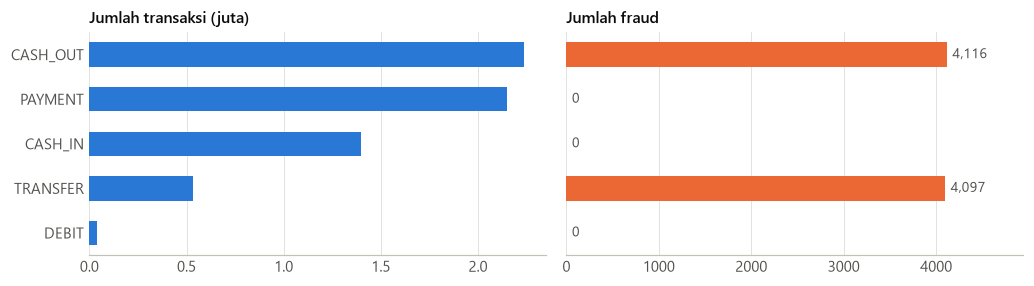

,transaksi,fraud,persen_transaksi,rasio_fraud_%
type,,,,
CASH_OUT,2237500,4116,35.1663,0.1840
PAYMENT,2151495,0,33.8146,0.0000
CASH_IN,1399284,0,21.9923,0.0000
TRANSFER,532909,4097,8.3756,0.7688
DEBIT,41432,0,0.6512,0.0000


In [39]:
ringkas_tipe = df.groupby("type", observed=True)["isFraud"].agg(transaksi="size", fraud="sum").sort_values("transaksi", ascending=False)
ringkas_tipe["persen_transaksi"] = ringkas_tipe["transaksi"] / len(df) * 100
ringkas_tipe["rasio_fraud_%"] = ringkas_tipe["fraud"] / ringkas_tipe["transaksi"] * 100
ringkas_tipe.to_csv(DIR_HASIL / "ringkas_tipe.csv")

fig, ax = plt.subplots(1, 2, figsize=(9.5, 2.7), sharey=True)
r = ringkas_tipe.iloc[::-1]
ax[0].barh(r.index.astype(str), r["transaksi"] / 1e6, height=0.55, color=WARNA_KELAS["normal"])
ax[0].set_title("Jumlah transaksi (juta)")
ax[1].barh(r.index.astype(str), r["fraud"], height=0.55, color=WARNA_KELAS["fraud"])
ax[1].set_title("Jumlah fraud")
for i, v in enumerate(r["fraud"]):
    ax[1].text(v + 60, i, f"{v:,}", va="center", fontsize=9, color=TINTA2)
ax[1].set_xlim(0, r["fraud"].max() * 1.2)
for a in ax:
    a.grid(axis="y", visible=False)
fig.tight_layout()
simpan(fig, "fig01_tipe_transaksi")
M.update(fraud_transfer=int(ringkas_tipe.loc["TRANSFER", "fraud"]), fraud_cashout=int(ringkas_tipe.loc["CASH_OUT", "fraud"]),
         rate_transfer=float(ringkas_tipe.loc["TRANSFER", "rasio_fraud_%"]), rate_cashout=float(ringkas_tipe.loc["CASH_OUT", "rasio_fraud_%"]))
ringkas_tipe

- **Temuan:** fraud hanya terjadi pada `TRANSFER` dan `CASH_OUT`.
- **Bukti:** … fraud pada `TRANSFER` (…%) dan … pada `CASH_OUT` (…%); tipe lain nol.
- **Implikasi:** pemodelan dibatasi pada kedua tipe ini. Ukuran data turun tanpa kehilangan satu pun kasus fraud.

### C.3 Nominal transaksi

**Koreksi:** notebook Pertemuan 2 menyatakan nominal fraud "cenderung lebih besar" pada kedua tipe. Untuk `TRANSFER`, median fraud justru lebih kecil daripada median normal.

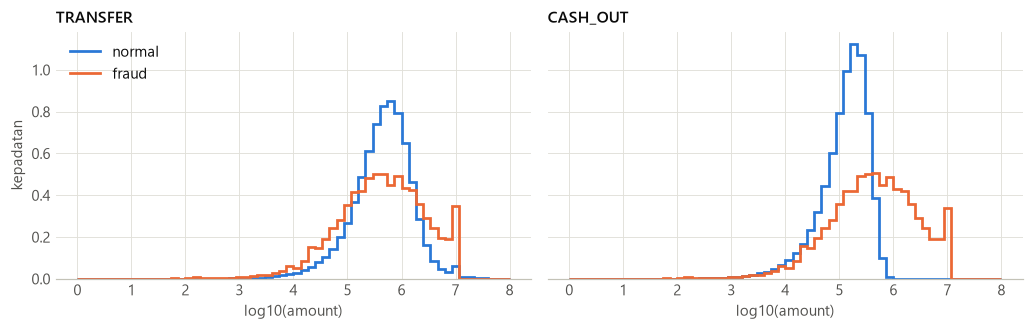

size       median           mean             max
type     isFraud                                                     
CASH_OUT 0        2233384 146,946.5600   173,917.1558  2,847,566.6200
         1           4116 435,516.9050 1,455,102.5860 10,000,000.0000
TRANSFER 0         528812 486,521.9100   906,229.0078 92,445,516.6400
         1           4097 445,705.7600 1,480,891.6729 10,000,000.0000

In [40]:
lingkup = df["type"].isin(LINGKUP_TIPE)
nominal = df[lingkup].groupby(["type", "isFraud"], observed=True)["amount"].agg(["size", "median", "mean", "max"])
nominal.to_csv(DIR_HASIL / "nominal_per_kelas.csv")

bins = np.linspace(0, 8, 61)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.1), sharey=True)
for a, tipe in zip(ax, LINGKUP_TIPE):
    s = df.loc[(df["type"] == tipe) & (df["amount"] > 0), ["amount", "isFraud"]]
    for kls, nama in [(0, "normal"), (1, "fraud")]:
        h_, e_ = np.histogram(np.log10(s.loc[s["isFraud"] == kls, "amount"]), bins=bins, density=True)
        a.stairs(h_, e_, color=WARNA_KELAS[nama], lw=1.8, label=nama)
    a.set_title(tipe)
    a.set_xlabel("log10(amount)")
ax[0].set_ylabel("kepadatan")
ax[0].legend(loc="upper left")
fig.tight_layout()
simpan(fig, "fig02_amount_per_kelas")

for t, k in [("TRANSFER", "transfer"), ("CASH_OUT", "cashout")]:
    M[f"median_{k}_normal"] = float(nominal.loc[(t, 0), "median"])
    M[f"median_{k}_fraud"] = float(nominal.loc[(t, 1), "median"])
    M[f"mean_{k}_normal"] = float(nominal.loc[(t, 0), "mean"])
    M[f"mean_{k}_fraud"] = float(nominal.loc[(t, 1), "mean"])
nominal

- **Temuan:** pola nominal berbeda antar-tipe, dan `amount` sendirian tidak memisahkan kelas.
- **Bukti:** median `TRANSFER` fraud …, lebih **kecil** dari normal …; median `CASH_OUT` fraud …, lebih besar dari normal …. Rata-rata fraud lebih tinggi pada keduanya karena ekor panjang, dengan nominal fraud terbesar tepat ….
- **Implikasi:** `amount` perlu dipasangkan dengan `type`, sehingga model yang dapat menangkap interaksi berpeluang lebih baik. Distribusi sangat miring (skewness …), sehingga `log1p` dipakai pada preprocessing. Pencilan tidak dibuang karena fraud berada di ekor distribusi.

### C.4 Pola waktu dan pergeseran distribusi

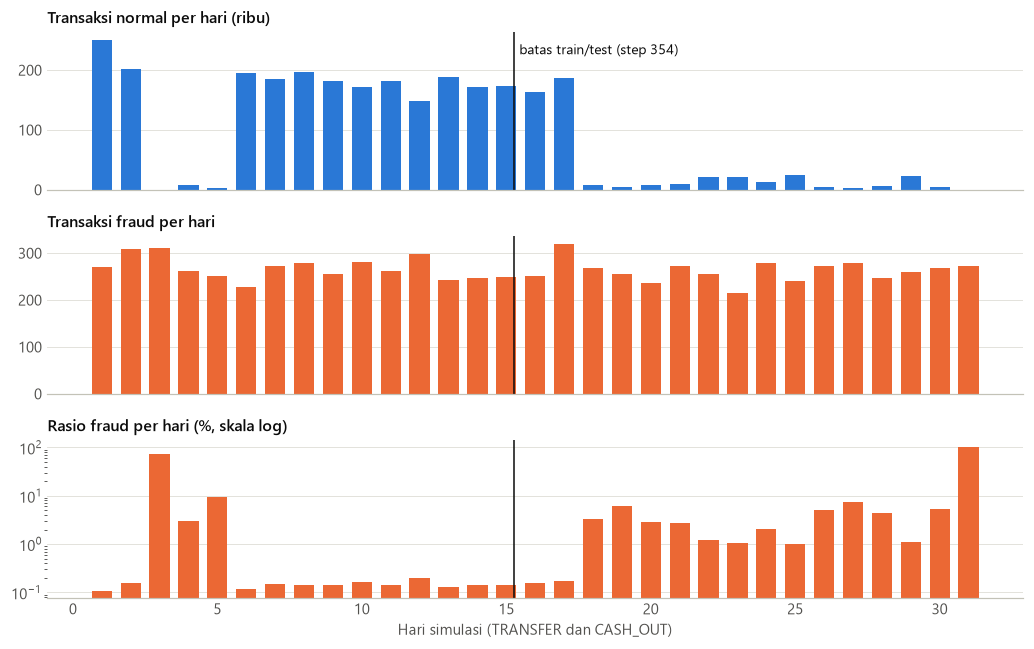

hari,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
transaksi,"251,083.0000","202,874.0000",429.0000,"8,766.0000","2,675.0000","195,910.0000","186,059.0000","197,042.0000","181,649.0000","171,830.0000","182,109.0000","149,340.0000","188,657.0000","172,524.0000","173,951.0000","163,144.0000","187,780.0000","8,068.0000","4,223.0000","8,142.0000","10,108.0000","21,529.0000","20,790.0000","13,774.0000","24,403.0000","5,458.0000","3,722.0000","5,724.0000","23,313.0000","5,061.0000",272.0000
fraud,271.0000,309.0000,310.0000,262.0000,252.0000,228.0000,272.0000,278.0000,255.0000,282.0000,262.0000,298.0000,242.0000,246.0000,250.0000,252.0000,320.0000,268.0000,256.0000,236.0000,272.0000,256.0000,216.0000,280.0000,240.0000,272.0000,280.0000,248.0000,260.0000,268.0000,272.0000
normal,"250,812.0000","202,565.0000",119.0000,"8,504.0000","2,423.0000","195,682.0000","185,787.0000","196,764.0000","181,394.0000","171,548.0000","181,847.0000","149,042.0000","188,415.0000","172,278.0000","173,701.0000","162,892.0000","187,460.0000","7,800.0000","3,967.0000","7,906.0000","9,836.0000","21,273.0000","20,574.0000","13,494.0000","24,163.0000","5,186.0000","3,442.0000","5,476.0000","23,053.0000","4,793.0000",0.0000
rasio_fraud_%,0.1080,0.1520,72.2610,2.9890,9.4210,0.1160,0.1460,0.1410,0.1400,0.1640,0.1440,0.2000,0.1280,0.1430,0.1440,0.1540,0.1700,3.3220,6.0620,2.8990,2.6910,1.1890,1.0390,2.0330,0.9830,4.9840,7.5230,4.3330,1.1150,5.2950,100.0000


In [41]:
def hitung_cutoff(step, porsi=PORSI_TRAIN):
    # Step terakhir yang masih termasuk train, sehingga +-80% baris paling awal masuk train dan satu step tidak terbelah.
    jumlah = pd.Series(step).value_counts().sort_index()
    return int(jumlah.index[np.searchsorted(jumlah.cumsum().to_numpy(), porsi * jumlah.sum())])


CUTOFF = hitung_cutoff(df.loc[lingkup, "step"])
M["cutoff"] = CUTOFF

per_hari = df.loc[lingkup, ["step", "isFraud"]].assign(hari=lambda d: (d["step"].astype(int) - 1) // 24 + 1)
per_hari = per_hari.groupby("hari")["isFraud"].agg(transaksi="size", fraud="sum")
per_hari["normal"] = per_hari["transaksi"] - per_hari["fraud"]
per_hari["rasio_fraud_%"] = per_hari["fraud"] / per_hari["transaksi"] * 100
per_hari.to_csv(DIR_HASIL / "volume_per_hari.csv")

hari_cut = CUTOFF / 24 + 0.5
fig, ax = plt.subplots(3, 1, figsize=(9.5, 6), sharex=True)
ax[0].bar(per_hari.index, per_hari["normal"] / 1e3, width=0.7, color=WARNA_KELAS["normal"])
ax[0].set_title("Transaksi normal per hari (ribu)")
ax[1].bar(per_hari.index, per_hari["fraud"], width=0.7, color=WARNA_KELAS["fraud"])
ax[1].set_title("Transaksi fraud per hari")
ax[2].bar(per_hari.index, per_hari["rasio_fraud_%"], width=0.7, color=WARNA_KELAS["fraud"])
ax[2].set_title("Rasio fraud per hari (%, skala log)")
ax[2].set_yscale("log")
ax[2].set_xlabel("Hari simulasi (TRANSFER dan CASH_OUT)")
for a in ax:
    a.axvline(hari_cut, color=TINTA, lw=1)
    a.grid(axis="x", visible=False)
ax[0].text(hari_cut + 0.2, ax[0].get_ylim()[1] * 0.86, f"batas train/test (step {CUTOFF})", fontsize=9, color=TINTA)
fig.tight_layout()
simpan(fig, "fig03_drift_waktu")

per_step = df.loc[lingkup].groupby("step")["isFraud"].sum()
M.update(fraud_per_step_mean=float(per_step.mean()), fraud_per_step_std=float(per_step.std()),
         rate_hari_min=float(per_hari["rasio_fraud_%"].min()), rate_hari_max=float(per_hari["rasio_fraud_%"].max()),
         normal_hari_maks=int(per_hari["normal"].max()), normal_hari_min=int(per_hari["normal"].min()))
per_hari.round(3).T

- **Temuan:** laju fraud hampir tetap sepanjang waktu, tetapi volume transaksi normal berubah drastis. Akibatnya rasio fraud bergeser jauh.
- **Bukti:** fraud rata-rata … per step (simpangan baku …), sementara transaksi normal per hari berkisar … hingga …. Rasio fraud harian bergerak dari …% hingga …%.
- **Implikasi:** pembagian acak menyembunyikan pergeseran ini dan mencampur masa depan ke data latih, sehingga evaluasi harus mengikuti waktu. PR-AUC antar periode juga tidak dapat dibandingkan tanpa melihat prevalensinya, karena nilai dasar PR-AUC sama dengan prevalensi.

### C.5 Pola jam dalam sehari

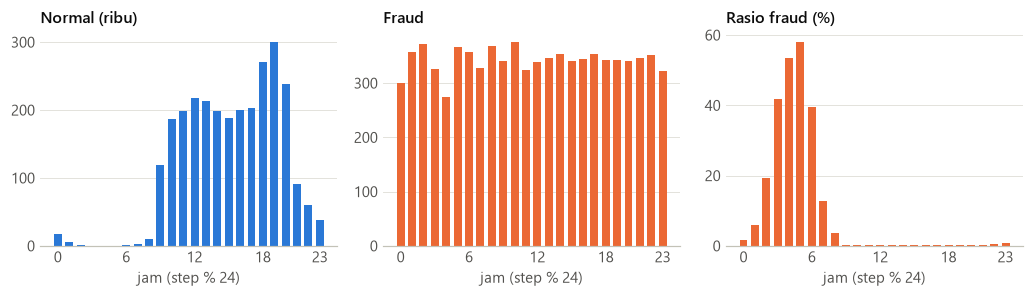

jam,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
transaksi,"18,214.0000","6,005.0000","1,922.0000",780.0000,512.0000,632.0000,904.0000,"2,542.0000","10,302.0000","120,028.0000","187,024.0000","198,240.0000","218,561.0000","213,906.0000","199,362.0000","188,136.0000","200,906.0000","202,806.0000","270,681.0000","299,933.0000","238,889.0000","90,926.0000","61,164.0000","38,034.0000"
fraud,300.0000,358.0000,372.0000,326.0000,274.0000,366.0000,358.0000,328.0000,368.0000,341.0000,375.0000,324.0000,339.0000,346.0000,353.0000,341.0000,345.0000,353.0000,343.0000,342.0000,340.0000,347.0000,351.0000,323.0000
normal,"17,914.0000","5,647.0000","1,550.0000",454.0000,238.0000,266.0000,546.0000,"2,214.0000","9,934.0000","119,687.0000","186,649.0000","197,916.0000","218,222.0000","213,560.0000","199,009.0000","187,795.0000","200,561.0000","202,453.0000","270,338.0000","299,591.0000","238,549.0000","90,579.0000","60,813.0000","37,711.0000"
rasio_fraud_%,1.6470,5.9620,19.3550,41.7950,53.5160,57.9110,39.6020,12.9030,3.5720,0.2840,0.2010,0.1630,0.1550,0.1620,0.1770,0.1810,0.1720,0.1740,0.1270,0.1140,0.1420,0.3820,0.5740,0.8490


In [42]:
per_jam = df.loc[lingkup, ["step", "isFraud"]].assign(jam=lambda d: d["step"] % 24)
per_jam = per_jam.groupby("jam")["isFraud"].agg(transaksi="size", fraud="sum")
per_jam["normal"] = per_jam["transaksi"] - per_jam["fraud"]
per_jam["rasio_fraud_%"] = per_jam["fraud"] / per_jam["transaksi"] * 100
per_jam.to_csv(DIR_HASIL / "pola_jam.csv")

fig, ax = plt.subplots(1, 3, figsize=(9.5, 2.8))
ax[0].bar(per_jam.index, per_jam["normal"] / 1e3, width=0.7, color=WARNA_KELAS["normal"])
ax[0].set_title("Normal (ribu)")
ax[1].bar(per_jam.index, per_jam["fraud"], width=0.7, color=WARNA_KELAS["fraud"])
ax[1].set_title("Fraud")
ax[2].bar(per_jam.index, per_jam["rasio_fraud_%"], width=0.7, color=WARNA_KELAS["fraud"])
ax[2].set_title("Rasio fraud (%)")
for a in ax:
    a.set_xlabel("jam (step % 24)")
    a.set_xticks([0, 6, 12, 18, 23])
    a.grid(axis="x", visible=False)
fig.tight_layout()
simpan(fig, "fig04_pola_jam")

M.update(rate_jam_maks=float(per_jam["rasio_fraud_%"].max()), jam_maks=int(per_jam["rasio_fraud_%"].idxmax()),
         rate_jam_min=float(per_jam["rasio_fraud_%"].min()), jam_min=int(per_jam["rasio_fraud_%"].idxmin()),
         fraud_jam_min=int(per_jam["fraud"].min()), fraud_jam_maks=int(per_jam["fraud"].max()),
         normal_jam_min=int(per_jam["normal"].min()), normal_jam_maks=int(per_jam["normal"].max()))
per_jam.round(3).T

- **Temuan:** jumlah fraud merata sepanjang hari, sedangkan transaksi normal mengikuti ritme harian.
- **Bukti:** fraud per jam berkisar …–…, sedangkan normal berkisar …–…. Rasio fraud mencapai …% pada jam ke-… dan hanya …% pada jam ke-….
- **Implikasi:** jam adalah fitur yang kuat, tetapi bersifat siklis (jam 23 dekat dengan jam 0). Fitur `jam_sin` dan `jam_cos` dibentuk pada bagian E.

### C.6 Perilaku kolom saldo

**Koreksi:** notebook Pertemuan 2 menyatakan "menguras saldo" jarang dilakukan pengguna normal, dengan definisi `amount >= oldbalanceOrg`. Definisi itu terlalu longgar. Pada transaksi normal dengan saldo positif, kondisi tersebut sangat umum.

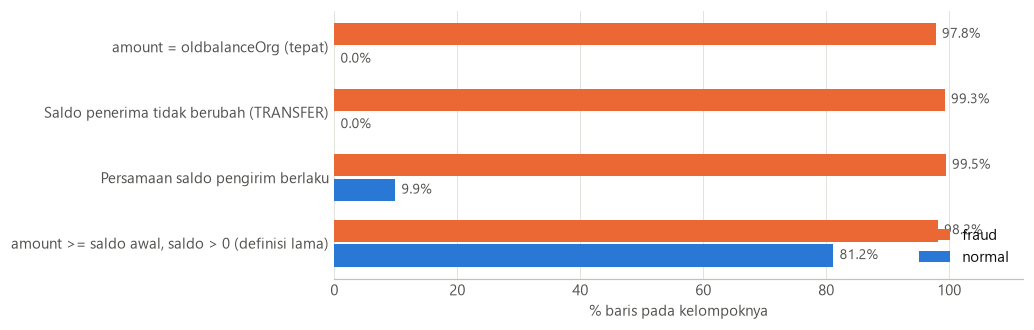

,fraud (%),normal (%)
amount = oldbalanceOrg (tepat),97.8205,0.0000
Saldo penerima tidak berubah (TRANSFER),99.2922,0.0202
Persamaan saldo pengirim berlaku,99.4521,9.9048
"amount >= saldo awal, saldo > 0 (definisi lama)",98.1645,81.1791


In [43]:
d = df.loc[lingkup, ["type", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]]
fr, no = d["isFraud"] == 1, d["isFraud"] == 0
tr_ = d["type"] == "TRANSFER"
sama_persis = d["amount"] == d["oldbalanceOrg"]
tujuan_tetap = np.isclose(d["oldbalanceDest"], d["newbalanceDest"], atol=0.01)
eq_asal = np.isclose(d["oldbalanceOrg"] - d["amount"], d["newbalanceOrig"], atol=0.01)
longgar = (d["amount"] >= d["oldbalanceOrg"] - 0.01)
positif = d["oldbalanceOrg"] > 0


def persen(mask, kelompok):
    return float(mask[kelompok].mean() * 100)


perilaku = pd.DataFrame({
    "fraud (%)": [persen(sama_persis, fr), persen(tujuan_tetap, fr & tr_), persen(eq_asal, fr), persen(longgar, fr & positif)],
    "normal (%)": [persen(sama_persis, no), persen(tujuan_tetap, no & tr_), persen(eq_asal, no), persen(longgar, no & positif)],
}, index=["amount = oldbalanceOrg (tepat)", "Saldo penerima tidak berubah (TRANSFER)",
          "Persamaan saldo pengirim berlaku", "amount >= saldo awal, saldo > 0 (definisi lama)"])
perilaku.to_csv(DIR_HASIL / "perilaku_saldo.csv")

fig, ax = plt.subplots(figsize=(9.5, 3.1))
y = np.arange(len(perilaku))[::-1]
ax.barh(y + 0.19, perilaku["fraud (%)"], height=0.34, color=WARNA_KELAS["fraud"], label="fraud")
ax.barh(y - 0.19, perilaku["normal (%)"], height=0.34, color=WARNA_KELAS["normal"], label="normal")
for yi, (a_, b_) in zip(y, perilaku.to_numpy()):
    ax.text(a_ + 1, yi + 0.19, f"{a_:.1f}%", va="center", fontsize=9, color=TINTA2)
    ax.text(b_ + 1, yi - 0.19, f"{b_:.1f}%", va="center", fontsize=9, color=TINTA2)
ax.set_yticks(y, perilaku.index)
ax.set_xlim(0, 112)
ax.set_xlabel("% baris pada kelompoknya")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
simpan(fig, "fig05_perilaku_saldo")

M.update(pct_sama_fraud=perilaku.iloc[0, 0], pct_sama_normal=perilaku.iloc[0, 1], n_sama_normal=int((sama_persis & no).sum()),
         n_sama_fraud=int((sama_persis & fr).sum()), n_normal_lingkup=int(no.sum()),
         pct_tetap_fraud=perilaku.iloc[1, 0], pct_tetap_normal=perilaku.iloc[1, 1],
         pct_eq_fraud=perilaku.iloc[2, 0], pct_eq_normal=perilaku.iloc[2, 1],
         pct_longgar_fraud=perilaku.iloc[3, 0], pct_longgar_normal=perilaku.iloc[3, 1])
del d, sama_persis, tujuan_tetap, eq_asal, longgar, positif, fr, no, tr_
gc.collect()
perilaku

- **Temuan:** kolom saldo memuat pola yang terlalu bersih untuk dianggap perilaku wajar.
- **Bukti:** `amount` sama persis dengan `oldbalanceOrg` pada …% fraud (… baris) dan pada **… dari … transaksi normal**. Saldo penerima tidak berubah pada …% `TRANSFER` fraud berbanding …% normal. Persamaan saldo pengirim justru berlaku pada …% fraud tetapi hanya …% transaksi normal. Definisi longgar yang lama menghasilkan …% berbanding …%, sehingga tidak menunjukkan pola sebenarnya.
- **Implikasi:** satu kesamaan nilai sudah hampir memisahkan kelas. Pola ini kemungkinan besar berasal dari cara simulator menyisipkan fraud, bukan sesuatu yang dapat diharapkan pada data nyata. Temuan ini mendukung catatan dokumentasi dataset. Skor tinggi yang bersandar pada kolom ini tidak menunjukkan kemampuan model.

### C.7 Korelasi antarvariabel numerik

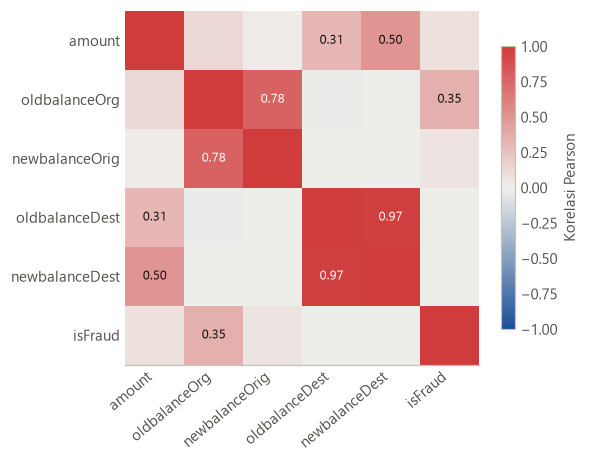

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
amount,1.0000,0.1200,0.0180,0.3070,0.4970,0.0710
oldbalanceOrg,0.1200,1.0000,0.7790,-0.0200,-0.0100,0.3480
newbalanceOrig,0.0180,0.7790,1.0000,-0.0120,-0.0150,0.0640
oldbalanceDest,0.3070,-0.0200,-0.0120,1.0000,0.9700,-0.0150
newbalanceDest,0.4970,-0.0100,-0.0150,0.9700,1.0000,-0.0090
isFraud,0.0710,0.3480,0.0640,-0.0150,-0.0090,1.0000


In [44]:
korelasi = df.loc[lingkup, ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]].corr()
korelasi.to_csv(DIR_HASIL / "korelasi.csv")

from matplotlib.colors import LinearSegmentedColormap

biru_merah = LinearSegmentedColormap.from_list("biru_merah", ["#184f95", "#f0efec", "#d03b3b"])
fig, ax = plt.subplots(figsize=(5.4, 4.3))
im = ax.imshow(korelasi, cmap=biru_merah, vmin=-1, vmax=1)
ax.set_xticks(range(len(korelasi)), korelasi.columns, rotation=40, ha="right")
ax.set_yticks(range(len(korelasi)), korelasi.index)
ax.grid(False)
for i in range(len(korelasi)):
    for j in range(len(korelasi)):
        v = korelasi.iat[i, j]
        if abs(v) >= 0.3 and i != j:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="#ffffff" if abs(v) > 0.7 else TINTA)
fig.colorbar(im, ax=ax, shrink=0.8, label="Korelasi Pearson")
fig.tight_layout()
simpan(fig, "fig06_korelasi")
M.update(kor_org=float(korelasi.loc["oldbalanceOrg", "newbalanceOrig"]), kor_dest=float(korelasi.loc["oldbalanceDest", "newbalanceDest"]),
         kor_fraud_maks=float(korelasi["isFraud"].drop("isFraud").abs().max()))
korelasi.round(3)

- **Temuan:** saldo sebelum dan sesudah transaksi saling berkorelasi kuat, sedangkan korelasi linear dengan target rendah.
- **Bukti:** korelasi `oldbalanceOrg`–`newbalanceOrig` … dan `oldbalanceDest`–`newbalanceDest` … pada lingkup `TRANSFER`/`CASH_OUT`. Korelasi absolut terbesar dengan `isFraud` hanya ….
- **Implikasi:** hubungan dengan target tidak linear, sehingga model berbasis pohon layak diuji di samping Logistic Regression.

---
## D. Preprocessing

| Kondisi data | Langkah | Alasan |
|---|---|---|
| Tidak ada NaN, duplikat, atau nilai negatif (B.1) | Tidak ada imputasi atau penghapusan baris | Imputasi tidak diperlukan. Jika data baru memuat NaN, Logistic Regression akan gagal secara eksplisit dan masalah langsung terlihat |
| Fraud hanya pada dua tipe (C.2) | Filter `TRANSFER` dan `CASH_OUT` | Mengurangi data tanpa kehilangan fraud. Kondisi ini juga berlaku pada periode latih (diperiksa pada bagian G) |
| `isFlaggedFraud` hasil aturan simulator (B.1) | Dikeluarkan dari fitur | Bukan masukan yang valid untuk model; dipakai sebagai baseline aturan |
| `nameOrig`, `nameDest` nyaris unik | Tidak dipakai langsung | `nameOrig` hampir selalu unik. `nameDest` hanya dipakai untuk menghitung riwayat penerima dari step sebelumnya |
| Empat kolom saldo (B, C.6) | Dikeluarkan dari skenario utama | Dilarang dokumentasi dataset, dan terbukti membawa pola simulator |
| `amount` sangat miring dengan pencilan yang relevan (C.3) | `log1p` lalu `RobustScaler`; pencilan tidak dibuang | `log1p` meredam kemiringan, `RobustScaler` memakai median dan IQR sehingga tahan pencilan. Fraud justru berada di ekor distribusi |
| `type` tanpa urutan | *One-hot encoding* | Kategori tidak berurutan |
| Jam bersifat siklis (C.5) | Transformasi `sin` dan `cos` | Jam 23 dan jam 0 menjadi berdekatan |

**Pencegahan data leakage:**
1. **Kebocoran fitur:** fitur diuji dengan satu pertanyaan, yaitu apakah nilainya sudah tersedia saat transaksi diajukan. Kolom saldo sesudah transaksi gagal pada ujian ini.
2. **Kebocoran preprocessing:** `RobustScaler` dan `OneHotEncoder` berada di dalam `Pipeline`, sehingga di-*fit* ulang pada data latih setiap fold. Notebook lama melakukan transformasi sekali sebelum CV, sehingga fold validasi ikut memengaruhi statistik skala.
3. **Kebocoran waktu:** fitur riwayat hanya menghitung step yang lebih awal, dan data latih selalu mendahului data validasi.
4. **Kebocoran seleksi:** data uji tidak dipakai untuk memilih fitur, model, atau ambang.

In [45]:
KOLOM_LOG = ["amount", "oldbalanceOrg", "oldbalanceDest", "newbalanceOrig", "newbalanceDest", "dest_n_sebelum"]
KOLOM_SIGNED_LOG = ["selisih_saldo_asal", "selisih_saldo_tujuan"]
KOLOM_RASIO = ["rasio_amount_saldo_asal"]
KOLOM_SKALA = ["jam_dalam_hari"]
KOLOM_APA_ADANYA = ["jam_sin", "jam_cos", "dest_baru", "amount_sama_saldo", "saldo_tujuan_nol", "saldo_asal_terkuras"]
KOLOM_KATEGORI = ["type"]


def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def potong_rasio(x):
    return np.clip(x, 0, 10)


def buat_preprocessor(fitur):
    # Hanya kolom yang ada pada `fitur` yang dipakai, sehingga satu fungsi melayani semua skenario.
    pilih = lambda daftar: [c for c in daftar if c in fitur]
    bagian = [
        ("log", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("skala", RobustScaler())]), pilih(KOLOM_LOG)),
        ("signed_log", Pipeline([("slog", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
                                 ("skala", RobustScaler())]), pilih(KOLOM_SIGNED_LOG)),
        ("rasio", Pipeline([("potong", FunctionTransformer(potong_rasio, feature_names_out="one-to-one")),
                            ("skala", RobustScaler())]), pilih(KOLOM_RASIO)),
        ("skala", RobustScaler(), pilih(KOLOM_SKALA)),
        ("apa_adanya", "passthrough", pilih(KOLOM_APA_ADANYA)),
        ("kategori", OneHotEncoder(handle_unknown="ignore", sparse_output=False), pilih(KOLOM_KATEGORI)),
    ]
    return ColumnTransformer([b for b in bagian if b[2]], remainder="drop", verbose_feature_names_out=False)

---
## E. Initial Feature Engineering

Fitur disusun dalam tiga skenario berdasarkan **kapan informasinya tersedia** dan apakah memakai kolom saldo:

| Skenario | Isi | Status |
|---|---|---|
| **S1 — Utama** | Nominal, tipe, jam, riwayat penerima | Tersedia saat transaksi diajukan; tanpa kolom saldo |
| **S2 — Sensitivitas** | S1 + saldo sebelum transaksi dan turunannya | Tersedia saat diajukan, tetapi melanggar catatan dataset |
| **S3 — Kebocoran** | S2 + saldo sesudah transaksi dan turunannya | Tidak tersedia saat keputusan diambil |

| Fitur | Dibentuk dari | Skenario | Alasan dan dampak yang diharapkan |
|---|---|---|---|
| `jam_sin`, `jam_cos` | `step % 24` | S1 | Pola harian kuat (C.5). Bentuk siklis membantu model linear menangkap jam sepi |
| `dest_n_sebelum` | Jumlah transaksi ke `nameDest` pada step yang lebih awal | S1 | Penerima dana fraud diduga jarang punya riwayat. Hanya memakai masa lalu |
| `dest_baru` | `dest_n_sebelum == 0` | S1 | Penanda penerima yang belum pernah terlihat |
| `rasio_amount_saldo_asal` | `amount / oldbalanceOrg` | S2 | Mengukur porsi saldo yang dipindahkan |
| `amount_sama_saldo` | `amount == oldbalanceOrg` | S2 | Pola terkuras tepat (C.6) |
| `saldo_tujuan_nol` | `oldbalanceDest == 0` | S2 | Penerima tanpa saldo tercatat |
| `selisih_saldo_asal`, `selisih_saldo_tujuan` | Persamaan saldo | S3 | Dipertahankan dari Pertemuan 2 untuk mengukur kebocoran |
| `saldo_asal_terkuras` | `oldbalanceOrg > 0` dan `newbalanceOrig == 0` | S3 | Memakai saldo sesudah transaksi |

**Fitur yang dihapus dari Pertemuan 2:** `tujuan_merchant` bernilai konstan pada lingkup `TRANSFER`/`CASH_OUT`, sehingga tidak membawa informasi (dibuktikan pada sel berikut).

**Detail `dest_n_sebelum`.** Baris dalam satu step tidak diketahui urutan aslinya, dan pasangan fraud berada berdampingan di file. Karena itu, hitungan hanya memakai step yang **lebih awal**, bukan baris sebelumnya, agar urutan file tidak bocor ke fitur. Riwayat dihitung dari semua tipe transaksi sebelum filter lingkup.

In [46]:
# Riwayat penerima dihitung sebelum filter lingkup, dari seluruh tipe transaksi.
# df terurut menurut step, sehingga cumcount = jumlah kemunculan sebelumnya; 'min' per (penerima, step) membuang baris satu step.
kode_dest = pd.Series(pd.factorize(df["nameDest"])[0].astype("int32"), index=df.index)
hitung = df.groupby(kode_dest, sort=False).cumcount().astype("int32")
df["dest_n_sebelum"] = hitung.groupby([kode_dest, df["step"]], sort=False).transform("min").astype("int32")
M["n_merchant_lingkup"] = int(df.loc[lingkup, "nameDest"].str.startswith("M").sum())
del kode_dest, hitung
gc.collect()


def tambah_fitur(data):
    d = data.copy()
    jam = d["step"].astype(int) % 24
    d["jam_dalam_hari"] = jam.astype(float)
    d["jam_sin"] = np.sin(2 * np.pi * jam / 24)
    d["jam_cos"] = np.cos(2 * np.pi * jam / 24)
    d["dest_baru"] = (d["dest_n_sebelum"] == 0).astype(float)
    # S2: memakai saldo sebelum transaksi
    positif = d["oldbalanceOrg"] > 0
    d["rasio_amount_saldo_asal"] = (d["amount"] / d["oldbalanceOrg"].where(positif, 1.0)).where(positif, 0.0)
    d["amount_sama_saldo"] = (d["amount"] == d["oldbalanceOrg"]).astype(float)
    d["saldo_tujuan_nol"] = (d["oldbalanceDest"] == 0).astype(float)
    # S3: memakai saldo sesudah transaksi
    d["selisih_saldo_asal"] = d["oldbalanceOrg"] - d["amount"] - d["newbalanceOrig"]
    d["selisih_saldo_tujuan"] = d["oldbalanceDest"] + d["amount"] - d["newbalanceDest"]
    d["saldo_asal_terkuras"] = (positif & (d["newbalanceOrig"] == 0)).astype(float)
    return d


data = df.loc[lingkup].drop(columns=["nameOrig", "nameDest"]).reset_index(drop=True)
data = tambah_fitur(data)
del df, lingkup
gc.collect()

FITUR_S0 = ["amount", "type", "jam_dalam_hari"]
FITUR_S0_SIKLUS = ["amount", "type", "jam_sin", "jam_cos"]
FITUR_S1 = FITUR_S0_SIKLUS + ["dest_n_sebelum", "dest_baru"]
FITUR_S2 = FITUR_S1 + ["oldbalanceOrg", "oldbalanceDest", "rasio_amount_saldo_asal", "amount_sama_saldo", "saldo_tujuan_nol"]
FITUR_S3 = FITUR_S2 + ["newbalanceOrig", "newbalanceDest", "selisih_saldo_asal", "selisih_saldo_tujuan", "saldo_asal_terkuras"]

M.update(n_lingkup=len(data), n_fraud_lingkup=int(data["isFraud"].sum()), persen_fraud_lingkup=data["isFraud"].mean() * 100,
         n_fitur_s1=len(FITUR_S1), n_fitur_s2=len(FITUR_S2), n_fitur_s3=len(FITUR_S3))
assert not set(FITUR_S1) & {"oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"}

print(f"Baris dalam lingkup : {len(data):,} | fraud: {data['isFraud'].sum():,} ({data['isFraud'].mean() * 100:.4f}%)")
print(f"Penerima merchant dalam lingkup: {M['n_merchant_lingkup']} (fitur tujuan_merchant lama selalu 0)")
print("Fitur S1:", FITUR_S1)
print("Fitur S2:", FITUR_S2)
print("Fitur S3:", FITUR_S3)

Baris dalam lingkup : 2,770,409 | fraud: 8,213 (0.2965%)
Penerima merchant dalam lingkup: 0 (fitur tujuan_merchant lama selalu 0)
Fitur S1: ['amount', 'type', 'jam_sin', 'jam_cos', 'dest_n_sebelum', 'dest_baru']
Fitur S2: ['amount', 'type', 'jam_sin', 'jam_cos', 'dest_n_sebelum', 'dest_baru', 'oldbalanceOrg', 'oldbalanceDest', 'rasio_amount_saldo_asal', 'amount_sama_saldo', 'saldo_tujuan_nol']
Fitur S3: ['amount', 'type', 'jam_sin', 'jam_cos', 'dest_n_sebelum', 'dest_baru', 'oldbalanceOrg', 'oldbalanceDest', 'rasio_amount_saldo_asal', 'amount_sama_saldo', 'saldo_tujuan_nol', 'newbalanceOrig', 'newbalanceDest', 'selisih_saldo_asal', 'selisih_saldo_tujuan', 'saldo_asal_terkuras']


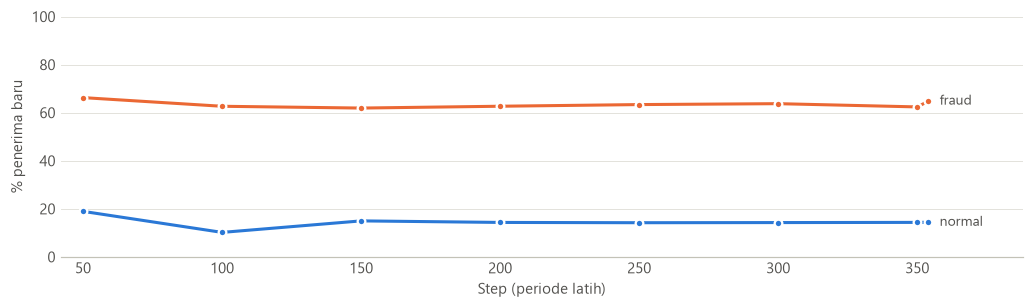

step,"(0, 50]","(50, 100]","(100, 150]","(150, 200]","(200, 250]","(250, 300]","(300, 350]","(350, 354]"
normal,18.9400,10.1800,14.9700,14.3300,14.2100,14.2700,14.3500,14.3900
fraud,66.2700,62.6700,61.9200,62.6800,63.3700,63.7500,62.4000,64.8100


In [47]:
# Pemeriksaan fitur riwayat pada PERIODE LATIH saja, supaya data uji tidak ikut memengaruhi keputusan fitur.
latih = data[data["step"] <= CUTOFF]
batas = list(range(0, CUTOFF, 50)) + [CUTOFF]
kelompok = pd.cut(latih["step"].astype(int), batas)
riwayat = latih.groupby([kelompok, "isFraud"], observed=True)["dest_baru"].mean().unstack() * 100
riwayat.columns = ["normal", "fraud"]
riwayat.to_csv(DIR_HASIL / "riwayat_penerima.csv")

fig, ax = plt.subplots(figsize=(9.5, 2.9))
x = [b.right for b in riwayat.index]
for kls in ["fraud", "normal"]:
    ax.plot(x, riwayat[kls], color=WARNA_KELAS[kls], marker="o", ms=5, mec="white", mew=1.5)
    ax.text(x[-1] + 4, riwayat[kls].iloc[-1], kls, va="center", color=TINTA2, fontsize=9)
ax.set_ylim(0, 100)
ax.set_xlim(x[0] - 8, x[-1] + 34)
ax.set_xlabel("Step (periode latih)")
ax.set_ylabel("% penerima baru")
ax.grid(axis="x", visible=False)
fig.tight_layout()
simpan(fig, "fig07_penerima_baru")

M.update(pct_baru_fraud=float(latih.loc[latih["isFraud"] == 1, "dest_baru"].mean() * 100),
         pct_baru_normal=float(latih.loc[latih["isFraud"] == 0, "dest_baru"].mean() * 100),
         pct_baru_fraud_min=float(riwayat["fraud"].min()), pct_baru_fraud_maks=float(riwayat["fraud"].max()),
         pct_baru_normal_min=float(riwayat["normal"].min()), pct_baru_normal_maks=float(riwayat["normal"].max()))
del latih
riwayat.round(2).T

- **Temuan:** penerima dana fraud lebih sering belum pernah muncul sebelumnya, dan polanya stabil sepanjang periode latih.
- **Bukti:** …% transaksi fraud menuju penerima baru, berbanding …% pada transaksi normal. Per jendela waktu, nilainya berkisar …–…% untuk fraud dan …–…% untuk normal.
- **Dampak yang diharapkan:** fitur ini tidak memakai kolom saldo sehingga layak masuk skenario utama, dan seharusnya menaikkan PR-AUC. Dampaknya diukur pada eksperimen E3.

---
## F. Baseline dan Model Kandidat Awal

| Peran | Model | Alasan |
|---|---|---|
| Referensi trivial | `DummyClassifier(prior)` | Menunjukkan batas bawah dan paradoks akurasi |
| Referensi aturan | `isFlaggedFraud` | Aturan bisnis yang sudah ada di data |
| Referensi aturan (hanya S2) | `amount == oldbalanceOrg` | Aturan satu baris dari C.6, untuk mengukur seberapa besar skor S2 berasal dari pola ini |
| **Baseline ML** | Logistic Regression | Sederhana dan mudah ditafsirkan. Dipertahankan dari Pertemuan 3–4 |
| Kandidat 1 | Decision Tree (`max_depth=12`) | Menangkap interaksi seperti `type` × `amount` (C.3) |
| Kandidat 2 | Random Forest (*bagging*) | Ensemble yang menurunkan varians pohon tunggal |
| Kandidat 3 | Histogram Gradient Boosting (*boosting*) | Ensemble bertahap, efisien untuk jutaan baris. Dipilih sebagai padanan XGBoost/LightGBM yang sudah tersedia di scikit-learn |

Konfigurasi hyperparameter sengaja tetap dan sederhana karena tuning menyeluruh termasuk tahap lanjutan. Dua pengaturan yang perlu dijelaskan:
`max_samples=0.1` pada Random Forest menghemat waktu latih, karena tiap pohon cukup melihat 10% baris.
`early_stopping=False` pada HGB mencegah pemisahan validasi internal yang bersifat acak, karena pemisahan itu akan melanggar urutan waktu.

In [48]:
MODEL_ML = ["LR", "DT", "RF", "HGB"]
NAMA_MODEL = {"LR": "Logistic Regression", "DT": "Decision Tree", "RF": "Random Forest", "HGB": "Hist. Gradient Boosting"}
L2_HGB = 10.0   # diperbarui dari hasil CV pada eksperimen E1


def buat_estimator(model, class_weight=None, l2=None):
    if model == "LR":
        return LogisticRegression(class_weight=class_weight, max_iter=1000, random_state=RANDOM_STATE)
    if model == "DT":
        return DecisionTreeClassifier(class_weight=class_weight, max_depth=12, min_samples_leaf=20, random_state=RANDOM_STATE)
    if model == "RF":
        return RandomForestClassifier(n_estimators=100, class_weight=class_weight, max_depth=12, min_samples_leaf=5,
                                      max_samples=0.1, n_jobs=-1, random_state=RANDOM_STATE)
    if model == "HGB":
        return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, l2_regularization=L2_HGB if l2 is None else l2,
                                              class_weight=class_weight, early_stopping=False, random_state=RANDOM_STATE)
    if model == "Dummy":
        return DummyClassifier(strategy="prior")
    raise ValueError(model)


def buat_pipeline(model, fitur, class_weight=None, l2=None):
    return Pipeline([("pre", buat_preprocessor(fitur)), ("model", buat_estimator(model, class_weight, l2))])

---
## G. Rancangan Evaluasi

**Audit strategi validasi (Tugas 1 Pertemuan 5):**

| Pertanyaan | Notebook Pertemuan 4 | Milestone 1 |
|---|---|---|
| Bagaimana data dibagi? | Acak bertingkat 80/20 | 80% baris paling awal untuk latih, sisanya uji, batas di tepi step |
| Perlukah validation set? | Tidak ada | Ya. Pemilihan memakai 5 fold jendela meluas di dalam periode latih; ambang dipilih dari fold terakhir |
| Sesuai jenis masalah? | Tidak. Masa depan ikut melatih model dan pasangan fraud terpisah | Ya. Model selalu dilatih dari masa lalu untuk memprediksi masa depan |
| Preprocessing hanya dari training? | Tidak saat CV; transformasi dilakukan sekali sebelum CV | Ya. `Pipeline` di-*fit* ulang setiap fold |
| Data test dipakai berulang? | Ya. Metrik test dihitung sebelum CV | Tidak. Satu kali, setelah pilihan dibekukan |

**Pembagian data.** Batas 80% dipakai karena sama dengan proporsi pada Pertemuan 2–4 dan ditetapkan dari jumlah baris, bukan dari hasil model. Satu step tidak pernah terbelah, sehingga pasangan fraud tidak terpisah.

**Validasi.** Periode latih dibagi menjadi enam blok berurutan dengan jumlah baris hampir sama. Fold ke-*k* berlatih pada blok 1..*k* dan divalidasi pada blok *k*+1.

**Metrik.**
- **Utama: PR-AUC** (*average precision*). Tidak bergantung ambang dan sesuai untuk kelas positif langka (Saito & Rehmsmeier, 2015). Nilai dasarnya sama dengan prevalensi, sehingga prevalensi selalu dilaporkan.
- **Pendukung:** ROC-AUC, yang tidak terpengaruh perubahan prevalensi. Precision, Recall, dan F1 pada ambang 0,5 selama CV. *Confusion matrix* pada hold-out.
- **Akurasi** hanya dicantumkan untuk memperlihatkan mengapa metrik ini menyesatkan.

**Aturan pemilihan.** Model dengan rata-rata PR-AUC tertinggi pada E2 (skenario S1, CV berbasis waktu). Data uji tidak terlibat.

In [49]:
train = data[data["step"] <= CUTOFF].reset_index(drop=True)
test = data[data["step"] > CUTOFF].reset_index(drop=True)   # tidak disentuh lagi sampai bagian H.7
del data
gc.collect()

y_train = train["isFraud"].to_numpy()

assert train["step"].max() < test["step"].min()
tipe_fraud_train = set(train.loc[train["isFraud"] == 1, "type"].astype(str))
assert tipe_fraud_train == set(LINGKUP_TIPE), tipe_fraud_train

ringkas_split = pd.DataFrame({
    "step": [f"{train['step'].min()}-{train['step'].max()}", f"{test['step'].min()}-{test['step'].max()}"],
    "baris": [len(train), len(test)],
    "fraud": [int(train["isFraud"].sum()), int(test["isFraud"].sum())],
    "prevalensi_%": [train["isFraud"].mean() * 100, test["isFraud"].mean() * 100],
}, index=["train", "test"])
ringkas_split.to_csv(DIR_HASIL / "pembagian_data.csv")
M.update(n_train=len(train), fraud_train=int(train["isFraud"].sum()), prev_train=train["isFraud"].mean() * 100,
         n_test=len(test), fraud_test=int(test["isFraud"].sum()), prev_test=test["isFraud"].mean() * 100,
         persen_baris_train=len(train) / (len(train) + len(test)) * 100,
         persen_fraud_train=train["isFraud"].sum() / (train["isFraud"].sum() + test["isFraud"].sum()) * 100)
ringkas_split

,step,baris,fraud,prevalensi_%
train,1-354,2217905,3955,0.1783
test,355-743,552504,4258,0.7707


In [50]:
def buat_fold_waktu(step, n_fold=N_FOLD):
    # Jendela meluas: n_fold + 1 blok berurutan dengan jumlah baris hampir sama, batas selalu di tepi step.
    step = np.asarray(step)
    jumlah = pd.Series(step).value_counts().sort_index()
    kum = jumlah.cumsum() / jumlah.sum()
    batas = [int(kum[kum >= i / (n_fold + 1)].index[0]) for i in range(1, n_fold + 2)]
    return [(np.flatnonzero(step <= batas[i]), np.flatnonzero((step > batas[i]) & (step <= batas[i + 1]))) for i in range(n_fold)]


FOLD_WAKTU = buat_fold_waktu(train["step"].to_numpy())
FOLD_ACAK = list(StratifiedKFold(N_FOLD, shuffle=True, random_state=RANDOM_STATE).split(np.zeros(len(y_train)), y_train))

tabel_fold = pd.DataFrame([{
    "fold": i,
    "step_latih": f"{train['step'].iloc[a].min()}-{train['step'].iloc[a].max()}",
    "n_latih": len(a), "fraud_latih": int(y_train[a].sum()),
    "step_validasi": f"{train['step'].iloc[b].min()}-{train['step'].iloc[b].max()}",
    "n_validasi": len(b), "fraud_validasi": int(y_train[b].sum()), "prevalensi_validasi_%": y_train[b].mean() * 100,
} for i, (a, b) in enumerate(FOLD_WAKTU, 1)])
tabel_fold.to_csv(DIR_HASIL / "rincian_fold.csv", index=False)
tabel_fold

,fold,step_latih,n_latih,fraud_latih,step_validasi,n_validasi,fraud_validasi,prevalensi_validasi_%
0,1,1-41,381727,484,42-159,366659,1330,0.3627
1,2,1-159,748386,1814,160-205,366728,480,0.1309
2,3,1-205,1115114,2294,206-254,367704,579,0.1575
3,4,1-254,1482818,2873,255-306,385633,582,0.1509
4,5,1-306,1868451,3455,307-354,349454,500,0.1431


In [51]:
METRIK = ["pr_auc", "roc_auc", "precision", "recall", "f1"]
hasil_fold = []


def hitung_metrik(y, skor, ambang=0.5):
    pred = (skor >= ambang).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "pr_auc": average_precision_score(y, skor), "roc_auc": roc_auc_score(y, skor),
        "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0), "accuracy": accuracy_score(y, pred),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def catat(eksperimen, peran, model, konfigurasi, skenario, validasi, fold, a, b, metrik, detik=0.0):
    hasil_fold.append({
        "eksperimen": eksperimen, "peran": peran, "model": model, "konfigurasi": konfigurasi, "skenario": skenario,
        "validasi": validasi, "fold": fold, "n_latih": len(a), "n_validasi": len(b), "prevalensi_validasi": y_train[b].mean(),
        **metrik, "detik": round(detik, 2),
    })


def cv_model(eksperimen, model, fitur, skenario, class_weight=None, l2=None, folds=None, validasi="Waktu 5-fold", konfigurasi=None):
    folds = FOLD_WAKTU if folds is None else folds
    konfigurasi = konfigurasi or ("class_weight=balanced" if class_weight else "tanpa penanganan")
    peran = {"LR": "Baseline ML", "Dummy": "Referensi"}.get(model, "Kandidat")
    X = train[fitur]
    for i, (a, b) in enumerate(folds, 1):
        t0 = time.time()
        pipa = buat_pipeline(model, fitur, class_weight, l2).fit(X.iloc[a], y_train[a])
        skor = pipa.predict_proba(X.iloc[b])[:, 1]
        catat(eksperimen, peran, model, konfigurasi, skenario, validasi, i, a, b, hitung_metrik(y_train[b], skor), time.time() - t0)


def cv_aturan(eksperimen, nama, skor_seluruh, skenario, folds=None, validasi="Waktu 5-fold"):
    folds = FOLD_WAKTU if folds is None else folds
    for i, (a, b) in enumerate(folds, 1):
        catat(eksperimen, "Referensi", nama, "aturan tetap", skenario, validasi, i, a, b, hitung_metrik(y_train[b], skor_seluruh[b]))


def ringkas(mask=None):
    d = pd.DataFrame(hasil_fold)
    if mask is not None:
        d = d[mask(d)]
    kunci = ["eksperimen", "peran", "model", "konfigurasi", "skenario", "validasi"]
    r = d.groupby(kunci, sort=False)[METRIK].agg(["mean", "std"])
    r.columns = [f"{m}_{s}" for m, s in r.columns]
    return r.reset_index()


def tampil(r, kolom=("model", "konfigurasi", "skenario", "validasi")):
    return r[list(kolom) + ["pr_auc_mean", "pr_auc_std", "roc_auc_mean", "roc_auc_std", "precision_mean", "recall_mean", "f1_mean"]]

---
## H. Hasil dan Analisis Awal

Seluruh eksperimen H.1–H.5 berjalan pada periode latih saja.

| ID | Pertanyaan | Skenario | Validasi |
|---|---|---|---|
| E1 | Apakah HGB stabil pada imbalance ekstrem? | S1 | Waktu 5-fold |
| E2 | Model mana yang terbaik, dan perlukah penanganan imbalance? | S1 | Waktu 5-fold |
| E3 | Apakah feature engineering berdampak? | S0, S0+siklus, S1 | Waktu 5-fold |
| E4 | Seberapa besar pengaruh cara validasi? | S1, S3 | Waktu vs acak bertingkat |
| E5 | Seberapa besar pengaruh kolom saldo? | S1, S2, S3 | Waktu 5-fold |
| E6 | Bagaimana performa akhir pada data yang belum pernah dipakai? | S1, S2, S3 | Hold-out |

### H.1 E1 — Stabilisasi Gradient Boosting

Uji awal HGB dengan pengaturan bawaan menghasilkan skor yang tidak masuk akal, sehingga penyebabnya diperiksa sebelum model dibandingkan.

In [52]:
for l2 in [0.0, 1.0, 10.0]:
    cv_model("E1", "HGB", FITUR_S1, "S1", l2=l2, konfigurasi=f"l2={l2:g}")

e1 = ringkas(lambda d: d["eksperimen"] == "E1")
L2_HGB = float(e1.sort_values("pr_auc_mean", ascending=False)["konfigurasi"].iloc[0].split("=")[1])
print("L2 terpilih dari CV:", L2_HGB)

# Diagnosis: rentang skor mentah pada fold terakhir, dihitung pada data latih fold tersebut.
a, b = FOLD_WAKTU[-1]
X_a = train.iloc[a][FITUR_S1]
diag = []
for l2 in [0.0, L2_HGB]:
    p_ = buat_pipeline("HGB", FITUR_S1, None, l2).fit(X_a, y_train[a])
    raw = p_.decision_function(X_a)
    diag.append({"l2": l2, "skor_mentah_min": raw.min(), "skor_mentah_maks": raw.max(), "pr_auc_pada_latih": average_precision_score(y_train[a], raw)})
diag = pd.DataFrame(diag)
diag.to_csv(DIR_HASIL / "diagnosis_hgb.csv", index=False)
del X_a, p_, raw
gc.collect()

e1_i = e1.set_index("konfigurasi")
M.update(e1_l2_terpilih=L2_HGB, e1_ap_l0=e1_i.loc["l2=0", "pr_auc_mean"], e1_sd_l0=e1_i.loc["l2=0", "pr_auc_std"],
         e1_ap_l1=e1_i.loc["l2=1", "pr_auc_mean"], e1_sd_l1=e1_i.loc["l2=1", "pr_auc_std"],
         e1_ap_l10=e1_i.loc["l2=10", "pr_auc_mean"], e1_sd_l10=e1_i.loc["l2=10", "pr_auc_std"],
         diag_min_l0=float(diag.loc[0, "skor_mentah_min"]), diag_maks_l0=float(diag.loc[0, "skor_mentah_maks"]),
         diag_ap_l0=float(diag.loc[0, "pr_auc_pada_latih"]), diag_min_lt=float(diag.loc[1, "skor_mentah_min"]),
         diag_maks_lt=float(diag.loc[1, "skor_mentah_maks"]), diag_ap_lt=float(diag.loc[1, "pr_auc_pada_latih"]))
display(tampil(e1, ("konfigurasi",)))
diag

L2 terpilih dari CV: 10.0


,konfigurasi,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,precision_mean,recall_mean,f1_mean
0,l2=0,0.1314,0.0717,0.7569,0.0674,0.2893,0.2200,0.2408
1,l2=1,0.3616,0.0306,0.9286,0.0096,0.6552,0.2728,0.3638
2,l2=10,0.3727,0.0398,0.9315,0.0085,0.7057,0.2674,0.3658


,l2,skor_mentah_min,skor_mentah_maks,pr_auc_pada_latih
0,0.0000,"-124,739.7567","44,911.3754",0.3206
1,10.0000,-12.1141,7.6826,0.4564


*(interpretasi `H1` diisi setelah eksekusi)*

### H.2 E2 — Baseline, kandidat, ensemble, dan penanganan imbalance

Setiap model dijalankan tanpa penanganan dan dengan `class_weight="balanced"` (bobot hanya dihitung dari data latih fold).

In [53]:
cv_model("E2", "Dummy", FITUR_S1, "S1", konfigurasi="prior")
cv_aturan("E2", "Aturan isFlaggedFraud", train["isFlaggedFraud"].to_numpy().astype(float), "S1")
for m in MODEL_ML:
    for cw in [None, "balanced"]:
        cv_model("E2", m, FITUR_S1, "S1", class_weight=cw)

e2 = ringkas(lambda d: d["eksperimen"] == "E2")
display(tampil(e2, ("model", "konfigurasi")).round(4))

# Konfigurasi terbaik per model dan model terpilih: keputusan diambil HANYA dari CV.
e2_ml = e2[e2["model"].isin(MODEL_ML)]
terbaik = e2_ml.sort_values("pr_auc_mean", ascending=False).groupby("model", sort=False).head(1)
KONFIG_TERBAIK = {r_["model"]: ("balanced" if "balanced" in r_["konfigurasi"] else None) for _, r_ in terbaik.iterrows()}
MODEL_TERPILIH = terbaik.iloc[0]["model"]
print("Konfigurasi imbalance terbaik per model:", KONFIG_TERBAIK)
print("Model terpilih:", MODEL_TERPILIH)

d_fold = pd.DataFrame(hasil_fold)
d_e2 = d_fold[(d_fold["eksperimen"] == "E2") & d_fold["model"].isin(MODEL_ML)]
dipakai = [(k == "class_weight=balanced") == (KONFIG_TERBAIK[m] == "balanced") for m, k in zip(d_e2["model"], d_e2["konfigurasi"])]
per_fold = d_e2[dipakai].pivot(index="fold", columns="model", values="pr_auc")[MODEL_ML]
stabil = pd.concat([per_fold, per_fold.mean().to_frame("Rata-rata").T, per_fold.std().to_frame("Standar deviasi").T])
stabil.to_csv(DIR_HASIL / "stabilitas_per_fold.csv")
stabil.round(4)

,model,konfigurasi,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,precision_mean,recall_mean,f1_mean
0,Dummy,prior,0.0019,0.0010,0.5000,0.0000,0.0000,0.0000,0.0000
1,Aturan isFlaggedFraud,aturan tetap,0.0029,0.0016,0.5005,0.0008,0.4000,0.0010,0.0021
2,LR,tanpa penanganan,0.1760,0.0281,0.8605,0.0243,0.7778,0.0097,0.0191
3,LR,class_weight=balanced,0.1986,0.0177,0.8653,0.0170,0.0083,0.7773,0.0165
4,DT,tanpa penanganan,0.2440,0.1316,0.8779,0.0583,0.4996,0.2421,0.2740
5,DT,class_weight=balanced,0.2684,0.1167,0.8129,0.0587,0.0302,0.6880,0.0576
6,RF,tanpa penanganan,0.3017,0.1413,0.9300,0.0074,0.4810,0.1671,0.2042
7,RF,class_weight=balanced,0.2422,0.1062,0.9277,0.0067,0.0413,0.7699,0.0779
8,HGB,tanpa penanganan,0.3727,0.0398,0.9315,0.0085,0.7057,0.2674,0.3658
9,HGB,class_weight=balanced,0.3310,0.0997,0.9258,0.0126,0.0401,0.7573,0.0743


Konfigurasi imbalance terbaik per model: {'HGB': None, 'RF': None, 'DT': 'balanced', 'LR': 'balanced'}
Model terpilih: HGB


model,LR,DT,RF,HGB
1,0.2096,0.3026,0.3622,0.4030
2,0.2237,0.3671,0.3599,0.3977
3,0.1874,0.3397,0.3698,0.3801
4,0.1914,0.0725,0.0490,0.3041
5,0.1807,0.2602,0.3674,0.3787
Rata-rata,0.1986,0.2684,0.3017,0.3727
Standar deviasi,0.0177,0.1167,0.1413,0.0398


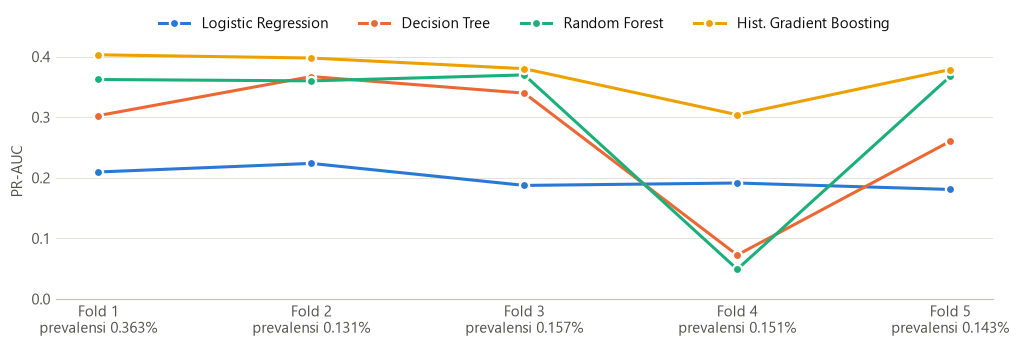

In [54]:
fig, ax = plt.subplots(figsize=(9.5, 3.3))
for m in MODEL_ML:
    ax.plot(per_fold.index, per_fold[m], color=WARNA_MODEL[m], marker="o", ms=6, mec="white", mew=1.5, label=NAMA_MODEL[m])
prev = tabel_fold.set_index("fold")["prevalensi_validasi_%"] / 100
ax.set_xticks(per_fold.index, [f"Fold {i}\nprevalensi {prev[i] * 100:.3f}%" for i in per_fold.index])
ax.set_ylabel("PR-AUC")
ax.set_ylim(0, None)
ax.grid(axis="x", visible=False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.16))
fig.tight_layout()
simpan(fig, "fig08_stabilitas_fold")

idx = lambda m: e2[(e2["model"] == m) & (e2["konfigurasi"] == ("class_weight=balanced" if KONFIG_TERBAIK.get(m) else "tanpa penanganan"))].iloc[0]
for m in MODEL_ML:
    r_ = idx(m)
    M.update({f"e2_ap_{m}": r_["pr_auc_mean"], f"e2_sd_{m}": r_["pr_auc_std"], f"e2_roc_{m}": r_["roc_auc_mean"], f"e2_rocsd_{m}": r_["roc_auc_std"],
              f"e2_cv_{m}": r_["pr_auc_std"] / r_["pr_auc_mean"] * 100, f"e2_cfg_{m}": r_["konfigurasi"],
              f"e2_f1_{m}": r_["f1_mean"], f"e2_p_{m}": r_["precision_mean"], f"e2_r_{m}": r_["recall_mean"]})
    for k, c in [("tanpa", "tanpa penanganan"), ("bal", "class_weight=balanced")]:
        s = e2[(e2["model"] == m) & (e2["konfigurasi"] == c)].iloc[0]
        M.update({f"e2_{k}_ap_{m}": s["pr_auc_mean"], f"e2_{k}_sd_{m}": s["pr_auc_std"], f"e2_{k}_r_{m}": s["recall_mean"],
                  f"e2_{k}_p_{m}": s["precision_mean"], f"e2_{k}_f1_{m}": s["f1_mean"], f"e2_{k}_roc_{m}": s["roc_auc_mean"]})
dm = e2[e2["model"] == "Dummy"].iloc[0]
ar = e2[e2["model"] == "Aturan isFlaggedFraud"].iloc[0]
M.update(e2_ap_dummy=dm["pr_auc_mean"], e2_ap_flag=ar["pr_auc_mean"], e2_r_flag=ar["recall_mean"], e2_p_flag=ar["precision_mean"],
         model_terpilih=MODEL_TERPILIH, nama_terpilih=NAMA_MODEL[MODEL_TERPILIH],
         cfg_terpilih=M[f"e2_cfg_{MODEL_TERPILIH}"], ap_terpilih=M[f"e2_ap_{MODEL_TERPILIH}"], sd_terpilih=M[f"e2_sd_{MODEL_TERPILIH}"],
         rasio_ap_vs_lr=M[f"e2_ap_{MODEL_TERPILIH}"] / M["e2_ap_LR"], prev_fold_min=float(tabel_fold["prevalensi_validasi_%"].min()),
         prev_fold_maks=float(tabel_fold["prevalensi_validasi_%"].max()))

*(interpretasi `H2` diisi setelah eksekusi)*

### H.3 E3 — Dampak feature engineering

Membandingkan fitur mentah, penambahan jam siklis, dan penambahan riwayat penerima pada baseline dan model terpilih.

In [55]:
model_e3 = list(dict.fromkeys(["LR", MODEL_TERPILIH]))
for m in model_e3:
    for nama, fitur in [("S0 mentah", FITUR_S0), ("S0 + jam siklis", FITUR_S0_SIKLUS), ("S1 (+ riwayat penerima)", FITUR_S1)]:
        cv_model("E3", m, fitur, nama, class_weight=KONFIG_TERBAIK[m])

e3 = ringkas(lambda d: d["eksperimen"] == "E3")
for _, r_ in e3.iterrows():
    k = {"S0 mentah": "s0", "S0 + jam siklis": "s0c", "S1 (+ riwayat penerima)": "s1"}[r_["skenario"]]
    t = "lr" if r_["model"] == "LR" else "pilih"
    M.update({f"e3_ap_{k}_{t}": r_["pr_auc_mean"], f"e3_sd_{k}_{t}": r_["pr_auc_std"], f"e3_roc_{k}_{t}": r_["roc_auc_mean"]})
tampil(e3, ("model", "skenario")).round(4)

,model,skenario,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,precision_mean,recall_mean,f1_mean
0,LR,S0 mentah,0.0148,0.0072,0.7709,0.0274,0.0059,0.6611,0.0117
1,LR,S0 + jam siklis,0.0562,0.0245,0.8097,0.0180,0.0057,0.7158,0.0112
2,LR,S1 (+ riwayat penerima),0.1986,0.0177,0.8653,0.0170,0.0083,0.7773,0.0165
3,HGB,S0 mentah,0.3070,0.0292,0.8728,0.0096,0.8455,0.1966,0.3176
4,HGB,S0 + jam siklis,0.3001,0.0314,0.8684,0.0130,0.8573,0.1953,0.3164
5,HGB,S1 (+ riwayat penerima),0.3727,0.0398,0.9315,0.0085,0.7057,0.2674,0.3658


*(interpretasi `H3` diisi setelah eksekusi)*

### H.4 E4 — Pengaruh cara validasi

Membandingkan CV berbasis waktu dengan CV acak bertingkat pada data yang sama, lalu menjalankan protokol lama (S3 dengan pembagian acak) sebagai pembanding langsung.

In [56]:
for m in MODEL_ML:
    cv_model("E4", m, FITUR_S1, "S1", class_weight=KONFIG_TERBAIK[m], folds=FOLD_ACAK, validasi="Acak bertingkat 5-fold")
    cv_model("E4", m, FITUR_S3, "S3", class_weight=KONFIG_TERBAIK[m], folds=FOLD_ACAK, validasi="Acak bertingkat 5-fold")

e4 = ringkas(lambda d: d["eksperimen"] == "E4")
acak = e4[e4["skenario"] == "S1"].set_index("model")
banding = pd.DataFrame({
    "PR-AUC waktu": [M[f"e2_ap_{m}"] for m in MODEL_ML], "sd waktu": [M[f"e2_sd_{m}"] for m in MODEL_ML],
    "PR-AUC acak": [acak.loc[m, "pr_auc_mean"] for m in MODEL_ML], "sd acak": [acak.loc[m, "pr_auc_std"] for m in MODEL_ML],
}, index=MODEL_ML)
banding["selisih (acak - waktu)"] = banding["PR-AUC acak"] - banding["PR-AUC waktu"]
banding.to_csv(DIR_HASIL / "banding_validasi.csv")
for m in MODEL_ML:
    M.update({f"e4_ap_{m}": banding.loc[m, "PR-AUC acak"], f"e4_sd_{m}": banding.loc[m, "sd acak"], f"e4_sel_{m}": banding.loc[m, "selisih (acak - waktu)"]})
lama = e4[e4["skenario"] == "S3"].set_index("model")
for m in MODEL_ML:
    M.update({f"e4lama_ap_{m}": lama.loc[m, "pr_auc_mean"], f"e4lama_f1_{m}": lama.loc[m, "f1_mean"]})
display(banding.round(4))
tampil(lama.reset_index(), ("model", "skenario", "validasi")).round(4)

,PR-AUC waktu,sd waktu,PR-AUC acak,sd acak,selisih (acak - waktu)
LR,0.1986,0.0177,0.1550,0.0162,-0.0436
DT,0.2684,0.1167,0.3723,0.0177,0.1038
RF,0.3017,0.1413,0.3931,0.0179,0.0914
HGB,0.3727,0.0398,0.4189,0.0137,0.0462


,model,skenario,validasi,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,precision_mean,recall_mean,f1_mean
0,LR,S3,Acak bertingkat 5-fold,0.9948,0.0020,0.9983,0.0009,0.8447,0.9932,0.9119
1,DT,S3,Acak bertingkat 5-fold,0.9928,0.0036,0.9962,0.0019,0.7699,0.9932,0.8668
2,RF,S3,Acak bertingkat 5-fold,0.9942,0.0022,0.9982,0.0008,1.0000,0.9922,0.9961
3,HGB,S3,Acak bertingkat 5-fold,0.9941,0.0026,0.9981,0.0004,0.9995,0.9922,0.9958


*(interpretasi `H4` diisi setelah eksekusi)*

### H.5 E5 — Pengaruh kolom saldo

Skenario S2 dan S3 memakai kolom yang dilarang dokumentasi. Keduanya hanya mengukur sensitivitas dan tidak ikut pemilihan model.

c:\Users\aswan\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


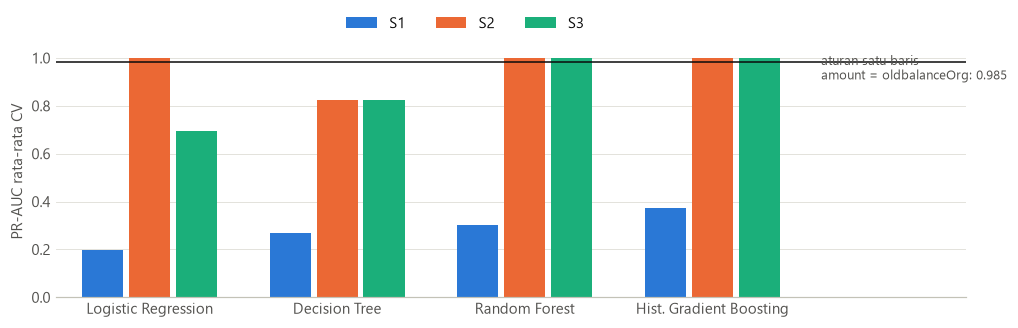

,S1,S2,S3
LR,0.1986,0.9986,0.6949
DT,0.2684,0.8237,0.8240
RF,0.3017,0.9984,0.9982
HGB,0.3727,0.9983,0.9982


,model,skenario,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,precision_mean,recall_mean,f1_mean
0,LR,S2,0.9986,0.0015,0.9998,0.0003,0.9427,0.9978,0.9694
1,LR,S3,0.6949,0.4171,0.9013,0.1351,0.5494,0.9689,0.5741
2,DT,S2,0.8237,0.3880,0.9979,0.0020,0.6530,0.9978,0.7464
3,DT,S3,0.8240,0.3881,0.9980,0.0020,0.6188,0.9982,0.7226
4,RF,S2,0.9984,0.0017,0.9998,0.0002,1.0000,0.9959,0.9980
5,RF,S3,0.9982,0.0019,0.9994,0.0005,1.0000,0.9945,0.9973
6,HGB,S2,0.9983,0.0017,0.9997,0.0005,1.0000,0.9960,0.9980
7,HGB,S3,0.9982,0.0019,0.9995,0.0008,1.0000,0.9968,0.9984
8,Aturan amount = oldbalanceOrg,S2,0.9852,0.0096,0.9926,0.0048,1.0000,0.9851,0.9925


In [57]:
for m in MODEL_ML:
    cv_model("E5", m, FITUR_S2, "S2", class_weight=KONFIG_TERBAIK[m])
    cv_model("E5", m, FITUR_S3, "S3", class_weight=KONFIG_TERBAIK[m])
cv_aturan("E5", "Aturan amount = oldbalanceOrg", train["amount_sama_saldo"].to_numpy(), "S2")

e5 = ringkas(lambda d: d["eksperimen"] == "E5")
skenario = pd.DataFrame({
    "S1": [M[f"e2_ap_{m}"] for m in MODEL_ML],
    "S2": [e5[(e5["model"] == m) & (e5["skenario"] == "S2")]["pr_auc_mean"].iloc[0] for m in MODEL_ML],
    "S3": [e5[(e5["model"] == m) & (e5["skenario"] == "S3")]["pr_auc_mean"].iloc[0] for m in MODEL_ML],
}, index=MODEL_ML)
skenario.to_csv(DIR_HASIL / "banding_skenario.csv")

fig, ax = plt.subplots(figsize=(9.5, 3.1))
aturan_ap = e5[e5["model"].str.startswith("Aturan")]["pr_auc_mean"].iloc[0]
x = np.arange(len(MODEL_ML))
warna_sk = {"S1": "#2a78d6", "S2": "#eb6834", "S3": "#1baf7a"}
for i, s in enumerate(["S1", "S2", "S3"]):
    ax.bar(x + (i - 1) * 0.25, skenario[s], width=0.22, color=warna_sk[s], label=s)
ax.axhline(aturan_ap, color=TINTA, lw=1)
ax.text(len(MODEL_ML) - 0.42, aturan_ap - 0.075, f"aturan satu baris\namount = oldbalanceOrg: {aturan_ap:.3f}", fontsize=8.5, color=TINTA2, ha="left")
ax.set_xticks(x, [NAMA_MODEL[m] for m in MODEL_ML])
ax.set_xlim(-0.5, len(MODEL_ML) + 0.35)
ax.set_ylim(0, 1.05)
ax.set_ylabel("PR-AUC rata-rata CV")
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.45, 1.17))
fig.tight_layout()
simpan(fig, "fig09_skenario")

for m in MODEL_ML:
    M.update({f"e5_s2_{m}": skenario.loc[m, "S2"], f"e5_s3_{m}": skenario.loc[m, "S3"]})
ar2 = e5[e5["model"].str.startswith("Aturan")].iloc[0]
M.update(e5_ap_aturan=ar2["pr_auc_mean"], e5_r_aturan=ar2["recall_mean"], e5_p_aturan=ar2["precision_mean"], e5_f1_aturan=ar2["f1_mean"])
display(skenario.round(4))
tampil(e5, ("model", "skenario")).round(4)

*(interpretasi `H5` diisi setelah eksekusi)*

### H.6 Diagnosis awal pada fold validasi terakhir

Diagnosis memakai fold 5, bukan data uji, agar temuan ini dapat dipakai untuk memperbaiki fitur setelah UTS tanpa mengotori data uji.

Ambang F1 maksimum pada fold 5: 0.4250
{'pr_auc': 0.3787, 'roc_auc': 0.9354, 'precision': 0.7745, 'recall': 0.316, 'f1': 0.4489, 'accuracy': 0.9989, 'tn': 348908.0, 'fp': 46.0, 'fn': 342.0, 'tp': 158.0}


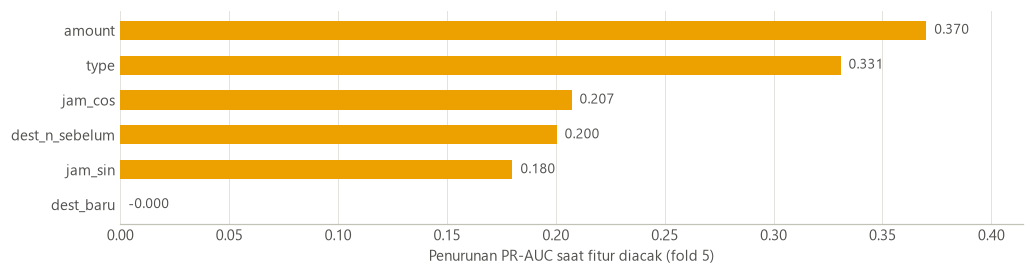

,dimensi,kelompok,fraud,recall
0,tipe,CASH_OUT,250,0.3640
1,tipe,TRANSFER,250,0.2680
0,penerima,baru,316,0.3006
1,penerima,lama,184,0.3424
0,jam,jam 0-8,192,0.5208
1,jam,jam 9-23,308,0.1883


In [58]:
def ambang_f1_maks(y, skor):
    p, r, t = precision_recall_curve(y, skor)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[int(np.argmax(f1))])


a, b = FOLD_WAKTU[-1]
pipa = buat_pipeline(MODEL_TERPILIH, FITUR_S1, KONFIG_TERBAIK[MODEL_TERPILIH]).fit(train.iloc[a][FITUR_S1], y_train[a])
X_val = train.iloc[b]
y_val = y_train[b]
skor_val = pipa.predict_proba(X_val[FITUR_S1])[:, 1]
ambang_val = ambang_f1_maks(y_val, skor_val)
pred_val = (skor_val >= ambang_val).astype(int)
print(f"Ambang F1 maksimum pada fold 5: {ambang_val:.4f}")
print(pd.Series(hitung_metrik(y_val, skor_val, ambang_val)).round(4).to_dict())

imp = permutation_importance(pipa, X_val[FITUR_S1], y_val, scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
pentingnya = pd.DataFrame({"fitur": FITUR_S1, "penurunan_pr_auc": imp.importances_mean, "sd": imp.importances_std}).sort_values("penurunan_pr_auc")
pentingnya.to_csv(DIR_HASIL / "kepentingan_fitur.csv", index=False)

fig, ax = plt.subplots(figsize=(9.5, 2.6))
ax.barh(pentingnya["fitur"], pentingnya["penurunan_pr_auc"], height=0.55, color=WARNA_MODEL.get(MODEL_TERPILIH, "#2a78d6"))
for i, v in enumerate(pentingnya["penurunan_pr_auc"]):
    ax.text(v + pentingnya["penurunan_pr_auc"].max() * 0.01, i, f"{v:.3f}", va="center", fontsize=9, color=TINTA2)
ax.set_xlim(0, pentingnya["penurunan_pr_auc"].max() * 1.12)
ax.set_xlabel("Penurunan PR-AUC saat fitur diacak (fold 5)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
simpan(fig, "fig10_kepentingan_fitur")

fraud_val = y_val == 1
kelompok_jam = np.where(X_val["jam_dalam_hari"].between(0, 8), "jam 0-8", "jam 9-23")
diagnosis = pd.DataFrame({
    "tipe": X_val["type"].astype(str).to_numpy(), "penerima": np.where(X_val["dest_baru"] == 1, "baru", "lama"),
    "jam": kelompok_jam, "tertangkap": pred_val,
})[fraud_val]
ringkas_diag = pd.concat([diagnosis.groupby(k)["tertangkap"].agg(fraud="size", recall="mean").rename_axis("kelompok").assign(dimensi=k).reset_index()
                          for k in ["tipe", "penerima", "jam"]])[["dimensi", "kelompok", "fraud", "recall"]]
ringkas_diag.to_csv(DIR_HASIL / "diagnosis_recall.csv", index=False)
g_ = ringkas_diag.set_index("kelompok")["recall"] * 100
M.update(ambang_val=ambang_val, diag_r_transfer=g_["TRANSFER"], diag_r_cashout=g_["CASH_OUT"], diag_r_baru=g_["baru"], diag_r_lama=g_["lama"],
         diag_r_malam=g_["jam 0-8"], diag_r_siang=g_["jam 9-23"], fitur_teratas=pentingnya["fitur"].iloc[-1], fitur_kedua=pentingnya["fitur"].iloc[-2],
         imp_teratas=float(pentingnya["penurunan_pr_auc"].iloc[-1]), imp_kedua=float(pentingnya["penurunan_pr_auc"].iloc[-2]))
del X_val, pipa
gc.collect()
ringkas_diag.round(4)

*(interpretasi `H6` diisi setelah eksekusi)*

### H.7 E6 — Evaluasi akhir pada hold-out (satu kali)

**Pilihan dibekukan sebelum sel ini dijalankan:** skenario S1, model terpilih dari E2, konfigurasi imbalance dari E2, L2 dari E1, ambang dari fold 5.
Semua model S1 ditampilkan agar perbandingannya lengkap, tetapi angka hold-out tidak dipakai untuk memilih apa pun. S2 dan S3 hanya untuk melihat sensitivitas.

In [59]:
y_test = test["isFraud"].to_numpy()
hasil_holdout = []
skor_test = {}


def holdout_model(model, fitur, skenario, cw):
    a_, b_ = FOLD_WAKTU[-1]
    p_ = buat_pipeline(model, fitur, cw).fit(train.iloc[a_][fitur], y_train[a_])
    ambang = ambang_f1_maks(y_train[b_], p_.predict_proba(train.iloc[b_][fitur])[:, 1])
    akhir = buat_pipeline(model, fitur, cw).fit(train[fitur], y_train)
    skor = akhir.predict_proba(test[fitur])[:, 1]
    skor_test[(model, skenario)] = (skor, ambang)
    hasil_holdout.append({"peran": "Baseline ML" if model == "LR" else "Kandidat", "model": model, "skenario": skenario,
                          "konfigurasi": "class_weight=balanced" if cw else "tanpa penanganan", "ambang": ambang, **hitung_metrik(y_test, skor, ambang)})


hasil_holdout.append({"peran": "Referensi", "model": "Dummy", "skenario": "S1", "konfigurasi": "prior", "ambang": 0.5,
                      **hitung_metrik(y_test, np.full(len(y_test), y_train.mean()))})
hasil_holdout.append({"peran": "Referensi", "model": "Aturan isFlaggedFraud", "skenario": "S1", "konfigurasi": "aturan tetap", "ambang": 0.5,
                      **hitung_metrik(y_test, test["isFlaggedFraud"].to_numpy().astype(float))})
hasil_holdout.append({"peran": "Referensi", "model": "Aturan amount = oldbalanceOrg", "skenario": "S2", "konfigurasi": "aturan tetap", "ambang": 0.5,
                      **hitung_metrik(y_test, test["amount_sama_saldo"].to_numpy())})
for m in MODEL_ML:
    holdout_model(m, FITUR_S1, "S1", KONFIG_TERBAIK[m])
for m in list(dict.fromkeys(["LR", MODEL_TERPILIH])):
    holdout_model(m, FITUR_S2, "S2", KONFIG_TERBAIK[m])
    holdout_model(m, FITUR_S3, "S3", KONFIG_TERBAIK[m])

holdout = pd.DataFrame(hasil_holdout)
holdout.to_csv(DIR_HASIL / "holdout.csv", index=False)
holdout[["model", "skenario", "ambang", "accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc", "tp", "fp", "fn", "tn"]].round(4)

,model,skenario,ambang,accuracy,precision,recall,f1,pr_auc,roc_auc,tp,fp,fn,tn
0,Dummy,S1,0.5000,0.9923,0.0000,0.0000,0.0000,0.0077,0.5000,0,0,4258,548246
1,Aturan isFlaggedFraud,S1,0.5000,0.9923,1.0000,0.0031,0.0061,0.0107,0.5015,13,0,4245,548246
2,Aturan amount = oldbalanceOrg,S2,0.5000,0.9998,1.0000,0.9753,0.9875,0.9755,0.9877,4153,0,105,548246
3,LR,S1,0.9714,0.9934,0.8750,0.1710,0.2861,0.3305,0.8714,728,104,3530,548142
4,DT,S1,0.9967,0.9943,0.8152,0.3408,0.4806,0.5240,0.8767,1451,329,2807,547917
5,RF,S1,0.3016,0.9945,0.8390,0.3499,0.4939,0.5616,0.9407,1490,286,2768,547960
6,HGB,S1,0.4250,0.9945,0.8777,0.3304,0.4801,0.5661,0.9424,1407,196,2851,548050
7,LR,S2,1.0000,0.9998,1.0000,0.9685,0.9840,1.0000,1.0000,4124,0,134,548246
8,LR,S3,0.9650,1.0000,1.0000,0.9939,0.9969,1.0000,1.0000,4232,0,26,548246
9,HGB,S2,0.9897,1.0000,1.0000,0.9948,0.9974,0.9999,1.0000,4236,0,22,548246


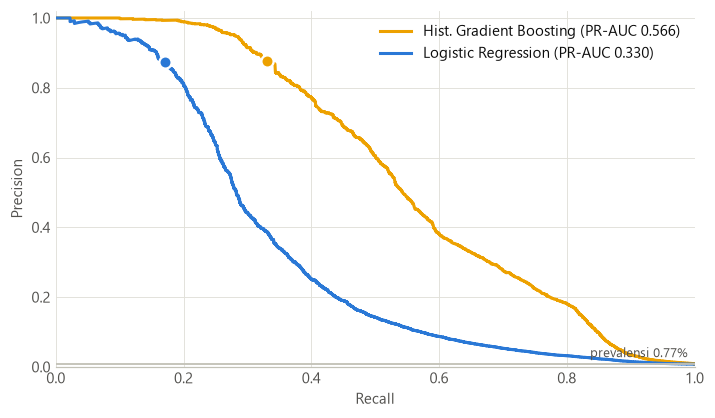

,segmen,baris,fraud,prevalensi_%,pr_auc,roc_auc,precision,recall,f1
0,355-400 (volume normal tinggi),311631,522,0.1675,0.5250,0.9366,0.8696,0.3831,0.5319
1,401-743 (volume normal rendah),240873,3736,1.5510,0.5985,0.9422,0.8791,0.3231,0.4725


In [60]:
fig, ax = plt.subplots(figsize=(6.6, 3.9))
kurva = [(MODEL_TERPILIH, "S1", WARNA_MODEL[MODEL_TERPILIH]), ("LR", "S1", WARNA_MODEL["LR"])]
for m, s, w in kurva:
    skor, ambang = skor_test[(m, s)]
    p, r, _ = precision_recall_curve(y_test, skor)
    b_ = holdout[(holdout["model"] == m) & (holdout["skenario"] == s)].iloc[0]
    ax.plot(r, p, color=w, lw=2, label=f"{NAMA_MODEL[m]} (PR-AUC {b_['pr_auc']:.3f})")
    ax.plot(b_["recall"], b_["precision"], "o", color=w, ms=8, mec="white", mew=1.5)
ax.axhline(y_test.mean(), color=GARIS, lw=1.2)
ax.text(0.99, y_test.mean() + 0.02, f"prevalensi {y_test.mean() * 100:.2f}%", ha="right", fontsize=8.5, color=TINTA2)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="upper right")
fig.tight_layout()
simpan(fig, "fig11_kurva_pr_holdout")

# Hold-out per rezim volume: model tetap sama, hanya prevalensi yang berubah.
skor, ambang = skor_test[(MODEL_TERPILIH, "S1")]
step_test = test["step"].to_numpy()
segmen = []
for nama, m_ in [(f"{CUTOFF + 1}-400 (volume normal tinggi)", step_test <= 400), ("401-743 (volume normal rendah)", step_test > 400)]:
    segmen.append({"segmen": nama, "baris": int(m_.sum()), "fraud": int(y_test[m_].sum()), "prevalensi_%": y_test[m_].mean() * 100,
                   **{k: v for k, v in hitung_metrik(y_test[m_], skor[m_], ambang).items() if k in ("pr_auc", "roc_auc", "precision", "recall", "f1")}})
segmen = pd.DataFrame(segmen)
segmen.to_csv(DIR_HASIL / "holdout_per_rezim.csv", index=False)

b_ = lambda m, s="S1": holdout[(holdout["model"] == m) & (holdout["skenario"] == s)].iloc[0]
for m in MODEL_ML:
    r_ = b_(m)
    M.update({f"h_ap_{m}": r_["pr_auc"], f"h_roc_{m}": r_["roc_auc"], f"h_p_{m}": r_["precision"], f"h_r_{m}": r_["recall"], f"h_f1_{m}": r_["f1"],
              f"h_tp_{m}": int(r_["tp"]), f"h_fp_{m}": int(r_["fp"]), f"h_fn_{m}": int(r_["fn"]), f"h_tn_{m}": int(r_["tn"]), f"h_acc_{m}": r_["accuracy"], f"h_amb_{m}": r_["ambang"]})
for k, m, s in [("dummy", "Dummy", "S1"), ("flag", "Aturan isFlaggedFraud", "S1"), ("aturan", "Aturan amount = oldbalanceOrg", "S2")]:
    r_ = b_(m, s)
    M.update({f"h_ap_{k}": r_["pr_auc"], f"h_p_{k}": r_["precision"], f"h_r_{k}": r_["recall"], f"h_f1_{k}": r_["f1"], f"h_acc_{k}": r_["accuracy"],
              f"h_tp_{k}": int(r_["tp"]), f"h_fp_{k}": int(r_["fp"]), f"h_fn_{k}": int(r_["fn"])})
for s in ["S2", "S3"]:
    r_ = b_(MODEL_TERPILIH, s)
    M.update({f"h_ap_pilih_{s}": r_["pr_auc"], f"h_r_pilih_{s}": r_["recall"], f"h_p_pilih_{s}": r_["precision"], f"h_f1_pilih_{s}": r_["f1"]})
    r_ = b_("LR", s)
    M.update({f"h_ap_lr_{s}": r_["pr_auc"], f"h_r_lr_{s}": r_["recall"], f"h_p_lr_{s}": r_["precision"], f"h_f1_lr_{s}": r_["f1"]})
M.update(h_ap_terpilih=M[f"h_ap_{MODEL_TERPILIH}"], h_roc_terpilih=M[f"h_roc_{MODEL_TERPILIH}"], h_p_terpilih=M[f"h_p_{MODEL_TERPILIH}"],
         h_r_terpilih=M[f"h_r_{MODEL_TERPILIH}"], h_f1_terpilih=M[f"h_f1_{MODEL_TERPILIH}"], h_tp_terpilih=M[f"h_tp_{MODEL_TERPILIH}"],
         h_fp_terpilih=M[f"h_fp_{MODEL_TERPILIH}"], h_fn_terpilih=M[f"h_fn_{MODEL_TERPILIH}"], h_amb_terpilih=M[f"h_amb_{MODEL_TERPILIH}"],
         h_lift=M[f"h_ap_{MODEL_TERPILIH}"] / (y_test.mean()),
         seg1_prev=segmen.loc[0, "prevalensi_%"], seg1_ap=segmen.loc[0, "pr_auc"], seg1_roc=segmen.loc[0, "roc_auc"], seg1_r=segmen.loc[0, "recall"], seg1_p=segmen.loc[0, "precision"],
         seg2_prev=segmen.loc[1, "prevalensi_%"], seg2_ap=segmen.loc[1, "pr_auc"], seg2_roc=segmen.loc[1, "roc_auc"], seg2_r=segmen.loc[1, "recall"], seg2_p=segmen.loc[1, "precision"])
segmen.round(4)

*(interpretasi `H7` diisi setelah eksekusi)*

---
## I. Dokumentasi: Tabel Hasil Eksperimen

Sel berikut menyusun **tabel hasil eksperimen awal** (`results/tabel_hasil_eksperimen.csv`), yang mencantumkan baseline, kandidat, metode validasi, metrik, dan hasil. Seluruh angka pada laporan berasal dari berkas pada `results/`.

In [61]:
d_fold = pd.DataFrame(hasil_fold)
d_fold.to_csv(DIR_HASIL / "cv_per_fold.csv", index=False)
cv = ringkas()
cv.to_csv(DIR_HASIL / "cv_ringkasan.csv", index=False)

baris_cv = cv.assign(
    **{"PR-AUC": cv["pr_auc_mean"].map("{:.4f}".format) + " ± " + cv["pr_auc_std"].map("{:.4f}".format),
       "ROC-AUC": cv["roc_auc_mean"].map("{:.4f}".format) + " ± " + cv["roc_auc_std"].map("{:.4f}".format),
       "Precision": cv["precision_mean"].map("{:.4f}".format), "Recall": cv["recall_mean"].map("{:.4f}".format), "F1": cv["f1_mean"].map("{:.4f}".format)}
)
baris_h = holdout.assign(
    eksperimen="E6", validasi=f"Hold-out kronologis (step > {CUTOFF})",
    **{"PR-AUC": holdout["pr_auc"].map("{:.4f}".format), "ROC-AUC": holdout["roc_auc"].map("{:.4f}".format), "Precision": holdout["precision"].map("{:.4f}".format),
       "Recall": holdout["recall"].map("{:.4f}".format), "F1": holdout["f1"].map("{:.4f}".format)}
)
kolom = ["eksperimen", "peran", "model", "konfigurasi", "skenario", "validasi", "PR-AUC", "ROC-AUC", "Precision", "Recall", "F1"]
tabel = pd.concat([baris_cv[kolom], baris_h[kolom]], ignore_index=True)
tabel.columns = ["ID", "Peran", "Model", "Konfigurasi", "Skenario fitur", "Metode validasi", "PR-AUC", "ROC-AUC", "Precision", "Recall", "F1"]
tabel.to_csv(DIR_HASIL / "tabel_hasil_eksperimen.csv", index=False, encoding="utf-8-sig")

M["durasi_menit"] = (time.time() - WAKTU_MULAI) / 60
M["versi"] = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "sklearn": sklearn.__version__, "matplotlib": matplotlib.__version__}
M["sha256"] = SHA256_ACUAN


def bersih(v):
    return v.item() if isinstance(v, np.generic) else v


(DIR_HASIL / "metrics.json").write_text(json.dumps({k: bersih(v) for k, v in M.items()}, indent=1, ensure_ascii=False, sort_keys=True), encoding="utf-8")
print(f"Baris tabel hasil: {len(tabel)} | durasi: {M['durasi_menit']:.1f} menit")
tabel.tail(14)

Baris tabel hasil: 47 | durasi: 20.7 menit


,ID,Peran,Model,Konfigurasi,Skenario fitur,Metode validasi,PR-AUC,ROC-AUC,Precision,Recall,F1
33,E5,Kandidat,HGB,tanpa penanganan,S2,Waktu 5-fold,0.9983 ± 0.0017,0.9997 ± 0.0005,1.0000,0.9960,0.9980
34,E5,Kandidat,HGB,tanpa penanganan,S3,Waktu 5-fold,0.9982 ± 0.0019,0.9995 ± 0.0008,1.0000,0.9968,0.9984
35,E5,Referensi,Aturan amount = oldbalanceOrg,aturan tetap,S2,Waktu 5-fold,0.9852 ± 0.0096,0.9926 ± 0.0048,1.0000,0.9851,0.9925
36,E6,Referensi,Dummy,prior,S1,Hold-out kronologis (step > 354),0.0077,0.5000,0.0000,0.0000,0.0000
37,E6,Referensi,Aturan isFlaggedFraud,aturan tetap,S1,Hold-out kronologis (step > 354),0.0107,0.5015,1.0000,0.0031,0.0061
38,E6,Referensi,Aturan amount = oldbalanceOrg,aturan tetap,S2,Hold-out kronologis (step > 354),0.9755,0.9877,1.0000,0.9753,0.9875
39,E6,Baseline ML,LR,class_weight=balanced,S1,Hold-out kronologis (step > 354),0.3305,0.8714,0.8750,0.1710,0.2861
40,E6,Kandidat,DT,class_weight=balanced,S1,Hold-out kronologis (step > 354),0.5240,0.8767,0.8152,0.3408,0.4806
41,E6,Kandidat,RF,tanpa penanganan,S1,Hold-out kronologis (step > 354),0.5616,0.9407,0.8390,0.3499,0.4939
42,E6,Kandidat,HGB,tanpa penanganan,S1,Hold-out kronologis (step > 354),0.5661,0.9424,0.8777,0.3304,0.4801


*(interpretasi `I` diisi setelah eksekusi)*